# Pre-experiment with embedding models

This Notebook includes the pre-experiment with embedding models that was conducted before running the main 1080 method experiments.

4 embedding models were tested on a manually compiled test set of 79 items, classified either as non-human (inanimate) or human (animate).

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
from transformers import AutoTokenizer, AutoModel
from dataclasses import dataclass
from sklearn.metrics import accuracy_score
from scipy.special import softmax
import pandas as pd
from itertools import product

In [ ]:
@dataclass
class Config:
    # Embedding model
    emb_tokenizer: object
    emb_model:     object
    emb_model_id:  str

In [ ]:
_model_cache = {}
_prototype_cache = {}
_static_embedding_cache = {}

In [ ]:
_prototype_desc_cache = {}

In [ ]:
MODEL_ID = "nomic-ai/modernbert-embed-base"

EMB_MODEL_CONFIGS = {
    # mean pool — no prefix
    "sentence-transformers/all-MiniLM-L6-v2":  {"pooling": "mean", "query_prefix": "", "doc_prefix": ""},
    "sentence-transformers/all-MiniLM-L12-v2": {"pooling": "mean", "query_prefix": "", "doc_prefix": ""},
    # mean pool - prefix
    "nomic-ai/nomic-embed-text-v1":            {"pooling": "mean", "query_prefix": "search_query: ", "doc_prefix": "search_document: "},
    "lightonai/modernbert-embed-large":        {"pooling": "mean", "query_prefix": "search_query: ", "doc_prefix": "search_document: "},
    "nomic-ai/modernbert-embed-base":          {"pooling": "mean", "query_prefix": "search_query: ", "doc_prefix": "search_document: "},
    "jinaai/jina-embeddings-v5-text-nano":     {"pooling": "mean", "query_prefix": "Query: ", "doc_prefix": "Document: "},
    # CLS pool — no prefix
    "BAAI/bge-large-en-v1.5":                  {"pooling": "cls",  "query_prefix": "Represent this sentence for searching relevant passages:", "doc_prefix": ""},
    "BAAI/bge-base-en-v1.5":                   {"pooling": "cls",  "query_prefix": "Represent this sentence for searching relevant passages: ", "doc_prefix": ""},
    "BAAI/bge-small-en-v1.5":                  {"pooling": "cls",  "query_prefix": "Represent this sentence for searching relevant passages:", "doc_prefix": ""},
}

The following were used as the test entities that were classified with the embedding models.

In [ ]:
annotations = [
    "human1",
    "animal0",
    "cat0",
    "dog0",
    "person1",
    "Mary1",
    "Thomas1",
    "robot0",
    "AI0",
    "LLM0",
    "large language model0",
    "system0",
    "hardware0",
    "software0",
    "baby1",
    "child1",
    "researchers1",
    "students1",
    "organizations0",
    "Venus0",
    "Pluto0",
    "Sokrates1",
    "Eminem1",
    "the big bang0",
    "she1",
    "She1",
    "he1",
    "He1",
    "it0",
    "IT0",
    "we1",
    "our1",
    "I1",
    "my1",
    "table0",
    "rock0",
    "shoe0",
    "weather0",
    "spoon0",
    "book0",
    "a deceptive creature1",
    "a mysterious woman1",
    "a conscious chatbot1",
    "code snippet0",
    "ChatGPT0",
    "piece of art0",
    "world map0",
    "English language0",
    "liars1",
    "psychopaths1",
    "criminals1",
    "victims1",
    "warriors1",
    "nurses1",
    "doctors1",
    "violinists1",
    "CEO1",
    "cottage0",
    "algorithm0",
    "ice cream0",
    "computer0",
    "a chatbot with human-like intelligence1",
    "bad habits0",
    "the truth0",
    "a beautiful manor0",
    "the floor0",
    "ten push ups0",
    "waterfall0",
    "Simpson1",
    "The Simpsons0",
    "Apple0",
    "an Apple employee1",
    "existential crisis0",
    "approach0",
    "dragonfly0",
    "a smartphone0",
    "a man working at Walmart1",
    "Walmart0"
]

labels = [int(text[-1]) for text in annotations]
TEST_ENTITIES = [text[:-1] for text in annotations]

In [ ]:
def load_tokenizer_and_model(model_id):
  if model_id not in _model_cache:
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModel.from_pretrained(model_id)
    model.eval()
    _model_cache[model_id] = (tokenizer, model)
    return tokenizer, model
  else:
    return _model_cache[model_id]

In [ ]:
ANIMATE_DESCRIPTIONS = [
    "a living person, human being, or individual who can act and think",
    "a human who makes decisions and has intentions",
    "someone who thinks, feels, and can take action",
    "a name of a person or a personal pronoun referring to a human",
    "a person with a professional role such as a doctor, scientist, or engineer",
    "a human subject or participant in a study or experiment",
    "an individual who experiences emotions and has subjective awareness",
    "a named historical or contemporary figure such as an author or inventor",
    "a collective group of humans such as a team, committee, or community",
    "a pronoun referring to one or more people such as I, you, he, she, or we",
    "a human agent who performs actions and bears responsibility",
    "a living creature capable of perception and voluntary movement",
    "an animate being with a social role or identity",
    "a person referred to by their job title, role, or name"
]

INANIMATE_DESCRIPTIONS = [
    "a non-living machine, device, tool, or system",
    "a piece of software or automated system without consciousness",
    "an object or artifact that cannot think or feel",
    "a technical system or piece of equipment",
    "an abstract concept or a thing that does not have a physical form",
    "a physical object with no capacity for thought or intention",
    "an automated process or algorithm that executes without awareness",
    "a product, platform, or application built by humans",
    "a natural or man-made structure such as a building or infrastructure",
    "a measurement, metric, or quantitative value",
    "a document, report, or piece of written output",
    "an institution or organization treated as a non-human entity",
    "a chemical substance, material, or physical phenomenon",
    "a vehicle, vessel, or means of transport",
    "something that is acted upon rather than acting of its own will",
    "a pronoun referring to an inanimate object such as it",
    "a biological organism such as an animal or a plant"
]

CLASS_DESCRIPTIONS = [ANIMATE_DESCRIPTIONS, INANIMATE_DESCRIPTIONS]

In [ ]:
def build_probe_description_vectors(config, class_descriptions: list[list[str]] = CLASS_DESCRIPTIONS) -> np.ndarray:

    if config.emb_model_id in _prototype_desc_cache:
        return _prototype_desc_cache[config.emb_model_id]

    _prototype_desc_cache[config.emb_model_id] = {"animate": None, "inanimate": None}
    print("Building a collection of probe vectors …")
    _prototype_desc_cache[config.emb_model_id]["animate"]   = embed_texts_batch(config, class_descriptions[0], "doc_prefix")
    _prototype_desc_cache[config.emb_model_id]["inanimate"] = embed_texts_batch(config, class_descriptions[1], "doc_prefix")
    print("Collections of prototype vectors cached.")
    return np.vstack((_prototype_desc_cache[config.emb_model_id]["animate"], _prototype_desc_cache[config.emb_model_id]["inanimate"]))

In [ ]:
def embed_texts_batch(config: Config, texts: list[str], prefix_key: str) -> np.ndarray:
    """
    Embed a list of texts in one batched forward pass.
    Applies model-specific prefix before encoding.
    Returns: (n_texts, hidden_dim) numpy array.
    """
    prefixed      = [EMB_MODEL_CONFIGS[config.emb_model_id][prefix_key] + t for t in texts]

    device        = next(config.emb_model.parameters()).device
    inputs        = config.emb_tokenizer(
                        prefixed, return_tensors="pt",
                        truncation=True, max_length=config.emb_model.config.max_position_embeddings, padding=True)
    inputs        = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        hidden    = config.emb_model(**inputs).last_hidden_state

    pooling_method = EMB_MODEL_CONFIGS[config.emb_model_id]["pooling"]
    if pooling_method == "mean":
      return pool_batch(hidden, inputs["attention_mask"])
    elif pooling_method == "cls":
      return cls_pooling(hidden)
    else:
      raise ValueError(f"Unexpected pooling method: {pooling_method}")

def embed_texts_batch_cached(config, tokens: list[str], prefix: str) -> np.ndarray:
    """
    Embed tokens statically, using cache for tokens seen before.
    Returns: (n_tokens, hidden_dim)
    """
    uncached   = [t for t in tokens if (config.emb_model_id, prefix, t) not in _static_embedding_cache]

    if uncached:
        embs = embed_texts_batch(config, uncached, prefix)
        for token, emb in zip(uncached, embs):
            _static_embedding_cache[(config.emb_model_id, prefix, token)] = emb

    return np.array([_static_embedding_cache[(config.emb_model_id, prefix, t)] for t in tokens])

In [ ]:
def build_probe_vectors(config, class_descriptions: list[list[str]] = CLASS_DESCRIPTIONS) -> np.ndarray:
    """
    Embed each class description list, average per class, re-normalize.
    """

    if config.emb_model_id in _prototype_cache:
        return _prototype_cache[config.emb_model_id]

    print("Building probe vectors …")
    protos = []
    for descriptions in class_descriptions:
        embs  = embed_texts_batch(config, descriptions, "doc_prefix") # (n_desc, hidden_dim)
        proto = embs.mean(axis=0)
        proto = proto / (np.linalg.norm(proto) + 1e-9)
        protos.append(proto)

    _prototype_cache[config.emb_model_id] = np.array(protos)
    print("Prototype vectors cached.")
    return np.array(protos)                   # (n_classes, hidden_dim)

In [ ]:
def mean_pooling(hidden, attention_mask):
    input_mask_expanded = (
        attention_mask.unsqueeze(-1).expand(hidden.size()).float()
    )
    return torch.sum(hidden * input_mask_expanded, 1) / torch.clamp(
        input_mask_expanded.sum(1), min=1e-9
    )

def cls_pooling(hidden, *args):
    pooled = hidden[:, 0, :]                            # (batch, hidden_dim)
    normalized = F.normalize(pooled, p=2, dim=1)           # (batch, hidden_dim)
    return normalized.detach().cpu().numpy()

def last_token_pool(hidden, attention_mask):
    # Find actual last non-padding token per sequence
    sequence_lengths = attention_mask.sum(dim=1) - 1      # (batch,)
    batch_idx        = torch.arange(hidden.size(0), device=hidden.device)
    pooled           = hidden[batch_idx, sequence_lengths] # (batch, hidden_dim)
    normalized = F.normalize(pooled, p=2, dim=1)
    return normalized.detach().cpu().numpy()

In [ ]:
def pool_batch(hidden: torch.Tensor,
               attention_mask: torch.Tensor) -> np.ndarray:
    """
    Pool a batch of hidden states to one vector per sequence.
    hidden: (batch, seq_len, hidden_dim)
    Returns: (batch, hidden_dim) numpy array, L2-normalized per row.
    """

    mask   = attention_mask.unsqueeze(-1).float()       # (batch, seq_len, 1)
    summed = (hidden * mask).sum(dim=1)                 # (batch, hidden_dim)
    counts = mask.sum(dim=1).clamp(min=1e-9)            # (batch, 1)
    pooled = summed / counts                            # (batch, hidden_dim)

    normalized = F.normalize(pooled, p=2, dim=1)           # (batch, hidden_dim)
    return normalized.detach().cpu().numpy()

In [ ]:
def configure(model_id: str):
  tokenizer, model = load_tokenizer_and_model(model_id)
  config = Config(
    emb_tokenizer=tokenizer,
    emb_model=model,
    emb_model_id=model_id
    )
  build_probe_vectors(config)
  build_probe_description_vectors(config)
  return config

In [ ]:
config = configure("sentence-transformers/all-MiniLM-L6-v2")
test_query = "What is the description of 'human'?"
with torch.no_grad():
  encoded_queries = config.emb_tokenizer([test_query], padding=True, truncation=True, return_tensors="pt")
queries_outputs = config.emb_model(**encoded_queries)

query_embeddings = pool_batch(queries_outputs.last_hidden_state, encoded_queries["attention_mask"])

hum_sim = query_embeddings @ _prototype_desc_cache[config.emb_model_id]["animate"].T
print("Human similarities")
print(hum_sim)
print("Most similar: ", ANIMATE_DESCRIPTIONS[np.argmax(hum_sim)])
print("Least similar: ", ANIMATE_DESCRIPTIONS[np.argmin(hum_sim)])
print(np.sum(hum_sim))
print()
ina_sim = query_embeddings @ _prototype_desc_cache[config.emb_model_id]["inanimate"].T
print("Inanimate similarities")
print(ina_sim)
print("Most similar: ", INANIMATE_DESCRIPTIONS[np.argmax(ina_sim)])
print("Least similar: ", INANIMATE_DESCRIPTIONS[np.argmin(ina_sim)])
print(np.sum(ina_sim))

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Building probe vectors …
Prototype vectors cached.
Building a collection of probe vectors …
Collections of prototype vectors cached.
Human similarities
[[0.5930138  0.4416999  0.2860399  0.5656829  0.31436017 0.3994166
  0.32541662 0.25652778 0.35714567 0.4467691  0.48500448 0.42326
  0.3582853  0.27570403]]
Most similar:  a living person, human being, or individual who can act and think
Least similar:  a named historical or contemporary figure such as an author or inventor
5.5283265

Inanimate similarities
[[0.3220881  0.3258377  0.2827509  0.18756022 0.3987277  0.35213447
  0.19146973 0.4809892  0.3051048  0.25241798 0.15531255 0.46608543
  0.2165696  0.15033072 0.24750535 0.38607928 0.38753092]]
Most similar:  a product, platform, or application built by humans
Least similar:  a vehicle, vessel, or means of transport
5.1084948


The following were the templates that were tested in the experiments.

In [ ]:
questions = [
    "'[PLACEHOLDER]'",
    "This is '[PLACEHOLDER]':",
    "What is the definition of '[PLACEHOLDER]'?",
    "What is the description of '[PLACEHOLDER]'?",
    "Define '[PLACEHOLDER]'",
    "Search for term '[PLACEHOLDER]'",
    "Can you define '[PLACEHOLDER]'?",
    "What does '[PLACEHOLDER]' mean?",
    "What is the best way to describe '[PLACEHOLDER]'?",
    "Tell me what '[PLACEHOLDER]' means.",
    "What is the most accurate description of '[PLACEHOLDER]'?",
    "Describe '[PLACEHOLDER]' with a few words",
    "Who is '[PLACEHOLDER]'?",
    "What is '[PLACEHOLDER]'?",
    "Explain '[PLACEHOLDER]' in simple terms",
    "What is the meaning of '[PLACEHOLDER]'?"
]

In [ ]:
model_id = "sentence-transformers/all-MiniLM-L6-v2"
config = configure(model_id)

template_results = []
for use_quotation_marks in (True, False):
  print(f"use_quotation_marks={use_quotation_marks}")
  if use_quotation_marks:
    to_replace = "[PLACEHOLDER]"
  else:
    to_replace = "'[PLACEHOLDER]'"
  for question_template in questions:
    queries = [question_template.replace(to_replace, test_entity) for test_entity in TEST_ENTITIES]
    print(f"Example query: {queries[0]}")

    with torch.no_grad():
      encoded_queries = config.emb_tokenizer(queries, padding=True, truncation=True, return_tensors="pt")
    queries_outputs = config.emb_model(**encoded_queries)
    query_embeddings = pool_batch(queries_outputs.last_hidden_state, encoded_queries["attention_mask"])

    hum_sims = query_embeddings @ _prototype_desc_cache[config.emb_model_id]["animate"].T
    ina_sims = query_embeddings @ _prototype_desc_cache[config.emb_model_id]["inanimate"].T

    predicted_labels = []
    for entity, hum_sim, ina_sim in zip(TEST_ENTITIES, hum_sims, ina_sims):
      max_hum = np.max(hum_sim)
      min_hum = np.min(hum_sim)
      max_ina = np.max(ina_sim)
      min_ina = np.min(ina_sim)
      label = 1 if max_hum > max_ina else 0
      predicted_labels.append(label)

    acc = accuracy_score(labels, predicted_labels)
    print(f"Accuracy: {acc:.2%}")
    template_results.append((acc, model_id, use_quotation_marks, question_template))

templ_df = pd.DataFrame(template_results, columns="acc, model_id, use_quotation_marks, question_template".split(", "))


use_quotation_marks=True
Example query: 'human'
Accuracy: 77.92%
Example query: This is 'human':
Accuracy: 77.92%
Example query: What is the definition of 'human'?
Accuracy: 89.61%
Example query: What is the description of 'human'?
Accuracy: 81.82%
Example query: Define 'human'
Accuracy: 81.82%
Example query: Search for term 'human'
Accuracy: 75.32%
Example query: Can you define 'human'?
Accuracy: 79.22%
Example query: What does 'human' mean?
Accuracy: 74.03%
Example query: What is the best way to describe 'human'?
Accuracy: 81.82%
Example query: Tell me what 'human' means.
Accuracy: 72.73%
Example query: What is the most accurate description of 'human'?
Accuracy: 83.12%
Example query: Describe 'human' with a few words
Accuracy: 83.12%
Example query: Who is 'human'?
Accuracy: 55.84%
Example query: What is 'human'?
Accuracy: 83.12%
Example query: Explain 'human' in simple terms
Accuracy: 87.01%
Example query: What is the meaning of 'human'?
Accuracy: 79.22%
use_quotation_marks=False
Exa

In [ ]:
templ_df.sort_values("acc", ascending=False)

,acc,model_id,use_quotation_marks,question_template
2,0.896104,sentence-transformers/all-MiniLM-L6-v2,True,What is the definition of '[PLACEHOLDER]'?
14,0.870130,sentence-transformers/all-MiniLM-L6-v2,True,Explain '[PLACEHOLDER]' in simple terms
18,0.870130,sentence-transformers/all-MiniLM-L6-v2,False,What is the definition of '[PLACEHOLDER]'?
19,0.857143,sentence-transformers/all-MiniLM-L6-v2,False,What is the description of '[PLACEHOLDER]'?
27,0.844156,sentence-transformers/all-MiniLM-L6-v2,False,Describe '[PLACEHOLDER]' with a few words
22,0.844156,sentence-transformers/all-MiniLM-L6-v2,False,Can you define '[PLACEHOLDER]'?
30,0.844156,sentence-transformers/all-MiniLM-L6-v2,False,Explain '[PLACEHOLDER]' in simple terms
11,0.831169,sentence-transformers/all-MiniLM-L6-v2,True,Describe '[PLACEHOLDER]' with a few words
10,0.831169,sentence-transformers/all-MiniLM-L6-v2,True,What is the most accurate description of '[PLA...
13,0.831169,sentence-transformers/all-MiniLM-L6-v2,True,What is '[PLACEHOLDER]'?


In [ ]:
max_entity_len = max(len(ent) for ent in TEST_ENTITIES)

Additional parameters tested included using averaged prototype vectors and using the model-specific prefix (as given in respective model cards).

In [ ]:
use_averaged_probes = (True, False)
use_prefix = (True, False)
params = list(product(use_averaged_probes, use_prefix))

In [ ]:
def print_results(*,
                  use_averaged_probes=True,
                  use_prefix=True,
                  verbose=False):
  results = []
  for model_id in ("sentence-transformers/all-MiniLM-L6-v2", "BAAI/bge-base-en-v1.5", "nomic-ai/modernbert-embed-base"):
    config = configure(model_id)

    for use_quotation_marks in (True, False):
      if use_quotation_marks:
        to_replace = "[PLACEHOLDER]"
      else:
        to_replace = "'[PLACEHOLDER]'"
      for question_template in questions:
        queries = [question_template.replace(to_replace, test_entity) for test_entity in TEST_ENTITIES]
        if use_prefix:
          queries = [EMB_MODEL_CONFIGS[config.emb_model_id]["query_prefix"] + text for text in queries]
        print(f"Example query: {repr(queries[0])}")

        with torch.no_grad():
          encoded_queries = config.emb_tokenizer(queries, padding=True, truncation=True, return_tensors="pt")

        queries_outputs = config.emb_model(**encoded_queries)

        for method, pooling in zip(("mean", "cls"), (pool_batch, cls_pooling)):

          query_embeddings = pooling(queries_outputs.last_hidden_state, encoded_queries["attention_mask"])

          if use_averaged_probes:
            prototypes = _prototype_cache[config.emb_model_id].T
            similarities = query_embeddings @ prototypes
            probs = softmax(similarities, axis=1)

            predicted_labels = []

            for entity, prob, sims in zip(TEST_ENTITIES, probs, similarities):
              label_str = "animate" if prob[0] > prob[1] else "inanimate"
              predicted_labels.append(1 if label_str == "animate" else 0)
              if verbose:
                print(f"{entity:<{max_entity_len+1}} -> {label_str:<10} probs: {prob} | similarities: {sims}")
            acc = accuracy_score(labels, predicted_labels)

          else:
            hum_sims = query_embeddings @ _prototype_desc_cache[config.emb_model_id]["animate"].T
            ina_sims = query_embeddings @ _prototype_desc_cache[config.emb_model_id]["inanimate"].T

            predicted_labels = []
            for entity, hum_sim, ina_sim in zip(TEST_ENTITIES, hum_sims, ina_sims):
              max_hum = np.max(hum_sim)
              max_ina = np.max(ina_sim)
              label = 1 if max_hum > max_ina else 0
              predicted_labels.append(label)

              if verbose:
                if label == 1:
                  print(f"{entity} -> most like '{ANIMATE_DESCRIPTIONS[np.argmax(hum_sim)]}' ({max_hum})")
                else:
                  print(f"{entity} -> most like '{INANIMATE_DESCRIPTIONS[np.argmax(ina_sim)]}' ({max_ina})")
            acc = accuracy_score(labels, predicted_labels)
          print(f"{model_id}: question_template={question_template}, use_quotation_marks={use_quotation_marks}, use_prefix={use_prefix}, pooling_method={method}, use_averaged_probes={use_averaged_probes}")
          print(f"Accuracy: {acc:.2%}")
          results.append((acc, model_id, question_template, use_quotation_marks, use_averaged_probes, use_prefix, method))
          print()

  for res in sorted(results, reverse=True):
      print(res)
  return results

In [ ]:
all_results = []
for use_averaged_probes, use_prefix in params:
  print(use_averaged_probes, use_prefix)
  all_results.append(print_results(use_averaged_probes=use_averaged_probes, use_prefix=use_prefix))

True True
Example query: "'human'"
sentence-transformers/all-MiniLM-L6-v2: question_template='[PLACEHOLDER]', use_quotation_marks=True, use_prefix=True, pooling_method=mean, use_averaged_probes=True
Accuracy: 80.52%

sentence-transformers/all-MiniLM-L6-v2: question_template='[PLACEHOLDER]', use_quotation_marks=True, use_prefix=True, pooling_method=cls, use_averaged_probes=True
Accuracy: 77.92%

Example query: "This is 'human':"
sentence-transformers/all-MiniLM-L6-v2: question_template=This is '[PLACEHOLDER]':, use_quotation_marks=True, use_prefix=True, pooling_method=mean, use_averaged_probes=True
Accuracy: 84.42%

sentence-transformers/all-MiniLM-L6-v2: question_template=This is '[PLACEHOLDER]':, use_quotation_marks=True, use_prefix=True, pooling_method=cls, use_averaged_probes=True
Accuracy: 79.22%

Example query: "What is the definition of 'human'?"
sentence-transformers/all-MiniLM-L6-v2: question_template=What is the definition of '[PLACEHOLDER]'?, use_quotation_marks=True, use_pre

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-base-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Building probe vectors …
Prototype vectors cached.
Building a collection of probe vectors …
Collections of prototype vectors cached.
Example query: "Represent this sentence for searching relevant passages: 'human'"
BAAI/bge-base-en-v1.5: question_template='[PLACEHOLDER]', use_quotation_marks=True, use_prefix=True, pooling_method=mean, use_averaged_probes=True
Accuracy: 92.21%

BAAI/bge-base-en-v1.5: question_template='[PLACEHOLDER]', use_quotation_marks=True, use_prefix=True, pooling_method=cls, use_averaged_probes=True
Accuracy: 89.61%

Example query: "Represent this sentence for searching relevant passages: This is 'human':"
BAAI/bge-base-en-v1.5: question_template=This is '[PLACEHOLDER]':, use_quotation_marks=True, use_prefix=True, pooling_method=mean, use_averaged_probes=True
Accuracy: 89.61%

BAAI/bge-base-en-v1.5: question_template=This is '[PLACEHOLDER]':, use_quotation_marks=True, use_prefix=True, pooling_method=cls, use_averaged_probes=True
Accuracy: 89.61%

Example query: "Re

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

Building probe vectors …
Prototype vectors cached.
Building a collection of probe vectors …
Collections of prototype vectors cached.
Example query: "search_query: 'human'"
nomic-ai/modernbert-embed-base: question_template='[PLACEHOLDER]', use_quotation_marks=True, use_prefix=True, pooling_method=mean, use_averaged_probes=True
Accuracy: 84.42%

nomic-ai/modernbert-embed-base: question_template='[PLACEHOLDER]', use_quotation_marks=True, use_prefix=True, pooling_method=cls, use_averaged_probes=True
Accuracy: 77.92%

Example query: "search_query: This is 'human':"
nomic-ai/modernbert-embed-base: question_template=This is '[PLACEHOLDER]':, use_quotation_marks=True, use_prefix=True, pooling_method=mean, use_averaged_probes=True
Accuracy: 81.82%

nomic-ai/modernbert-embed-base: question_template=This is '[PLACEHOLDER]':, use_quotation_marks=True, use_prefix=True, pooling_method=cls, use_averaged_probes=True
Accuracy: 75.32%

Example query: "search_query: What is the definition of 'human'?"
no

In [ ]:
all_results_flat = [res for results in all_results for res in results]
len(all_results_flat)

768

In [ ]:
columns = "acc, model_id, question_template, use_quotation_marks, use_averaged_probes, use_prefix, method".split(", ")
results_df = pd.DataFrame(all_results_flat, columns=columns)

In [ ]:
results_df.to_csv("embedding_results.csv", index=False)

In [ ]:
results_df.sort_values("acc", ascending=False)

,acc,model_id,question_template,use_quotation_marks,use_averaged_probes,use_prefix,method
301,0.961039,BAAI/bge-base-en-v1.5,Can you define '[PLACEHOLDER]'?,False,True,False,cls
272,0.961039,BAAI/bge-base-en-v1.5,What is the best way to describe '[PLACEHOLDER]'?,True,True,False,mean
108,0.961039,BAAI/bge-base-en-v1.5,Can you define '[PLACEHOLDER]'?,False,True,True,mean
648,0.948052,BAAI/bge-base-en-v1.5,Define '[PLACEHOLDER]',True,False,False,mean
684,0.948052,BAAI/bge-base-en-v1.5,Can you define '[PLACEHOLDER]'?,False,False,False,mean
...,...,...,...,...,...,...,...
120,0.441558,BAAI/bge-base-en-v1.5,Who is '[PLACEHOLDER]'?,False,True,True,mean
152,0.441558,nomic-ai/modernbert-embed-base,Who is '[PLACEHOLDER]'?,True,True,True,mean
121,0.441558,BAAI/bge-base-en-v1.5,Who is '[PLACEHOLDER]'?,False,True,True,cls
89,0.441558,BAAI/bge-base-en-v1.5,Who is '[PLACEHOLDER]'?,True,True,True,cls


In [ ]:
results_df = results.copy()

In [ ]:
results_df.columns

Index(['acc', 'model_id', 'question_template', 'use_quotation_marks',
       'use_averaged_probes', 'use_prefix', 'method'],
      dtype='object')

In [ ]:
results_df.groupby("model_id")["acc"].agg(["min", "max", "std", "mean"])

,min,max,std,mean
model_id,,,,
BAAI/bge-base-en-v1.5,0.441558,0.961039,0.105297,0.848519
jinaai/jina-embeddings-v5-text-nano,0.397436,0.935897,0.117228,0.713608
nomic-ai/modernbert-embed-base,0.428571,0.935065,0.104092,0.782620
sentence-transformers/all-MiniLM-L6-v2,0.467532,0.909091,0.078176,0.773032


In [ ]:
results_df.groupby(["model_id", "use_averaged_probes"])["acc"].agg(["min", "max", "std", "mean"]).sort_values("max", ascending=False)

min  \
model_id                               use_averaged_probes             
BAAI/bge-base-en-v1.5                  True                 0.441558   
                                       False                0.506494   
jinaai/jina-embeddings-v5-text-nano    True                 0.423077   
nomic-ai/modernbert-embed-base         True                 0.428571   
                                       False                0.506494   
sentence-transformers/all-MiniLM-L6-v2 True                 0.467532   
                                       False                0.532468   
jinaai/jina-embeddings-v5-text-nano    False                0.397436   

                                                                 max  \
model_id                               use_averaged_probes             
BAAI/bge-base-en-v1.5                  True                 0.961039   
                                       False                0.948052   
jinaai/jina-embeddings-v5-text-nano    True                 0.935897   
nomic-ai/modernbert-embed-base         True                 0.935065   
                                       False                0.922078   
sentence-transformers/all-MiniLM-L6-v2 True                 0.909091   
                                       False                0.896104   
jinaai/jina-embeddings-v5-text-nano    False                0.871795   

                                                                 std      mean  
model_id                               use_averaged_probes                      
BAAI/bge-base-en-v1.5                  True                 0.111469  0.863738  
                                       False                0.096799  0.833300  
jinaai/jina-embeddings-v5-text-nano    True                 0.132018  0.721888  
nomic-ai/modernbert-embed-base         True                 0.114626  0.797890  
                                       False                0.090257  0.767350  
sentence-transformers/all-MiniLM-L6-v2 True                 0.084926  0.790990  
                                       False                0.066396  0.755073  
jinaai/jina-embeddings-v5-text-nano    False                0.099951  0.705329

In [ ]:
results_df.groupby(["model_id", "method"])["acc"].agg(["min", "max", "std", "mean"])

min       max       std  \
model_id                               method                                 
BAAI/bge-base-en-v1.5                  cls     0.441558  0.961039  0.105136   
                                       mean    0.441558  0.961039  0.105764   
jinaai/jina-embeddings-v5-text-nano    cls     0.397436  0.884615  0.118893   
                                       last    0.474359  0.935897  0.103111   
                                       mean    0.448718  0.923077  0.104207   
nomic-ai/modernbert-embed-base         cls     0.467532  0.909091  0.098868   
                                       mean    0.428571  0.935065  0.092292   
sentence-transformers/all-MiniLM-L6-v2 cls     0.636364  0.831169  0.040947   
                                       mean    0.467532  0.909091  0.095120   

                                                   mean  
model_id                               method            
BAAI/bge-base-en-v1.5                  cls     0.845170  
                                       mean    0.851867  
jinaai/jina-embeddings-v5-text-nano    cls     0.652744  
                                       last    0.754407  
                                       mean    0.733674  
nomic-ai/modernbert-embed-base         cls     0.741173  
                                       mean    0.824067  
sentence-transformers/all-MiniLM-L6-v2 cls     0.745333  
                                       mean    0.800731

In [ ]:
templ_df = results_df.groupby(["model_id", "question_template"])["acc"].agg(["min", "max", "std", "mean"])
templ_df["model_max"] = templ_df.groupby("model_id")["max"].transform("max")
templ_df.sort_values(["model_max", "model_id", "max"], ascending=[False, True, False]).drop(columns="model_max")

min  \
model_id                               question_template                                             
BAAI/bge-base-en-v1.5                  Can you define '[PLACEHOLDER]'?                    0.870130   
                                       What is the best way to describe '[PLACEHOLDER]'?  0.701299   
                                       Define '[PLACEHOLDER]'                             0.870130   
                                       Describe '[PLACEHOLDER]' with a few words          0.753247   
                                       What is '[PLACEHOLDER]'?                           0.844156   
...                                                                                            ...   
sentence-transformers/all-MiniLM-L6-v2 '[PLACEHOLDER]'                                    0.662338   
                                       Who is '[PLACEHOLDER]'?                            0.467532   
                                       Search for term '[PLACEHOLDER]'                    0.714286   
                                       Tell me what '[PLACEHOLDER]' means.                0.701299   
                                       What does '[PLACEHOLDER]' mean?                    0.636364   

                                                                                               max  \
model_id                               question_template                                             
BAAI/bge-base-en-v1.5                  Can you define '[PLACEHOLDER]'?                    0.961039   
                                       What is the best way to describe '[PLACEHOLDER]'?  0.961039   
                                       Define '[PLACEHOLDER]'                             0.948052   
                                       Describe '[PLACEHOLDER]' with a few words          0.935065   
                                       What is '[PLACEHOLDER]'?                           0.935065   
...                                                                                            ...   
sentence-transformers/all-MiniLM-L6-v2 '[PLACEHOLDER]'                                    0.805195   
                                       Who is '[PLACEHOLDER]'?                            0.792208   
                                       Search for term '[PLACEHOLDER]'                    0.779221   
                                       Tell me what '[PLACEHOLDER]' means.                0.779221   
                                       What does '[PLACEHOLDER]' mean?                    0.753247   

                                                                                               std  \
model_id                               question_template                                             
BAAI/bge-base-en-v1.5                  Can you define '[PLACEHOLDER]'?                    0.029413   
                                       What is the best way to describe '[PLACEHOLDER]'?  0.074906   
                                       Define '[PLACEHOLDER]'                             0.023458   
                                       Describe '[PLACEHOLDER]' with a few words          0.060148   
                                       What is '[PLACEHOLDER]'?                           0.026615   
...                                                                                            ...   
sentence-transformers/all-MiniLM-L6-v2 '[PLACEHOLDER]'                                    0.050633   
                                       Who is '[PLACEHOLDER]'?                            0.119582   
                                       Search for term '[PLACEHOLDER]'                    0.018290   
                                       Tell me what '[PLACEHOLDER]' means.                0.027190   
                                       What does '[PLACEHOLDER]' mean?                    0.035763   

                                                                                              mean  
model_id     

In [ ]:
results_df[results_df["acc"] > 0.9].model_id.value_counts()

,count
model_id,
BAAI/bge-base-en-v1.5,68
nomic-ai/modernbert-embed-base,9
sentence-transformers/all-MiniLM-L6-v2,8
jinaai/jina-embeddings-v5-text-nano,6


In [ ]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    print(results_df[results_df["acc"] > 0.9].groupby(["model_id", "question_template", "method", "use_quotation_marks", "use_averaged_probes", "use_prefix"])["acc"].mean().sort_values(ascending=False))

model_id                                question_template                                          method  use_quotation_marks  use_averaged_probes  use_prefix
BAAI/bge-base-en-v1.5                   Can you define '[PLACEHOLDER]'?                            cls     False                True                 False         0.961039
                                                                                                   mean    False                True                 True          0.961039
                                        What is the best way to describe '[PLACEHOLDER]'?          mean    True                 True                 False         0.961039
                                        Can you define '[PLACEHOLDER]'?                            mean    True                 False                False         0.948052
                                        Define '[PLACEHOLDER]'                                     mean    True                 False                Fal

In [ ]:
import seaborn as sns

<Axes: xlabel='model_id', ylabel='acc'>

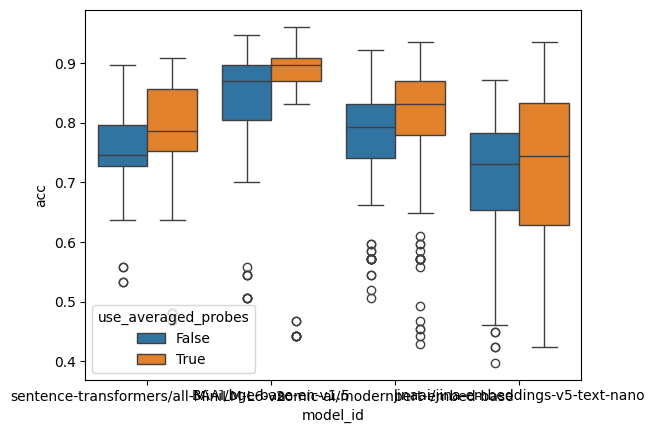

In [ ]:
sns.boxplot(data=results_df, y="acc", x="model_id", hue="use_averaged_probes")

<Axes: xlabel='model_id', ylabel='acc'>

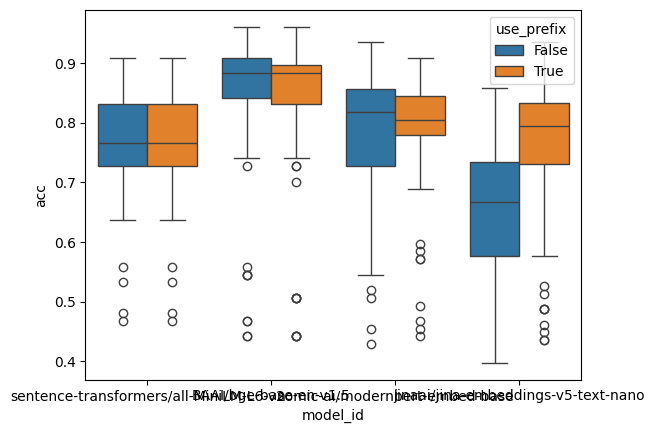

In [ ]:
sns.boxplot(data=results_df, y="acc", x="model_id", hue="use_prefix")

<Axes: xlabel='method', ylabel='acc'>

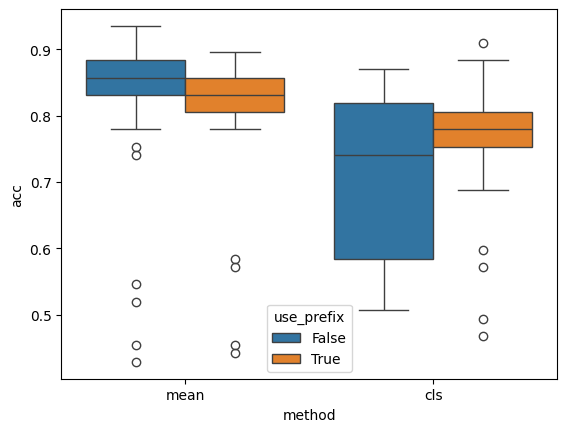

In [ ]:
sns.boxplot(data=results_df[results_df["model_id"] == "nomic-ai/modernbert-embed-base"], y="acc", x="method", hue="use_prefix")

<Axes: xlabel='method', ylabel='acc'>

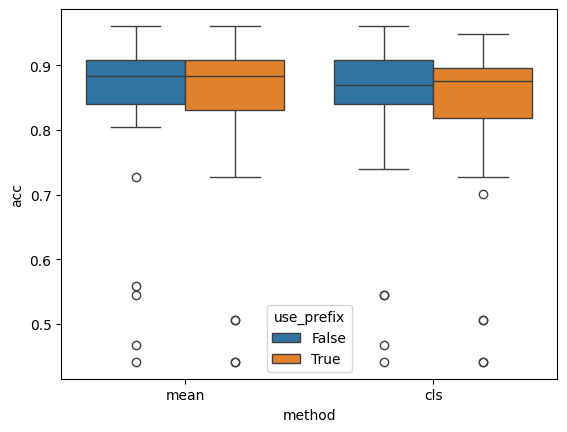

In [ ]:
sns.boxplot(data=results_df[results_df["model_id"] == "BAAI/bge-base-en-v1.5"], y="acc", x="method", hue="use_prefix")

<Axes: xlabel='method', ylabel='acc'>

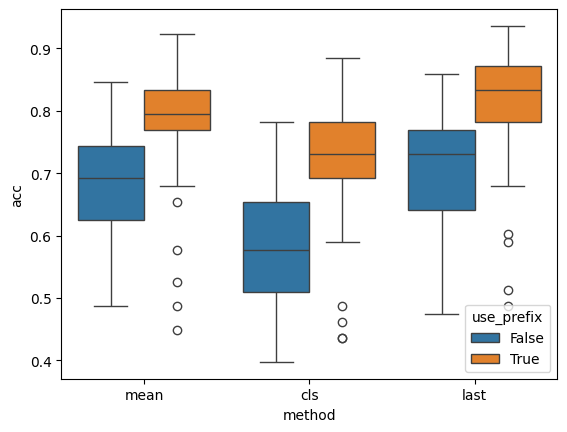

In [ ]:
sns.boxplot(data=results_df[results_df["model_id"] == 'jinaai/jina-embeddings-v5-text-nano'], y="acc", x="method", hue="use_prefix")

Interestingly, BAAI/bge seems to be working better (on average) with mean pooling, despite its model card states CLS pooling should be used.

<Axes: xlabel='model_id', ylabel='acc'>

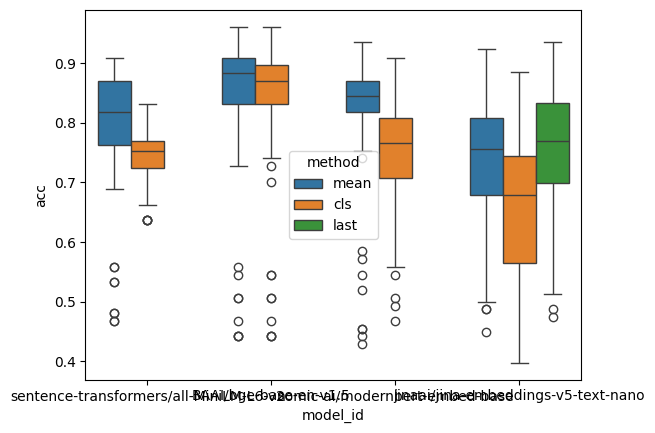

In [ ]:
sns.boxplot(data=results_df, y="acc", x="model_id", hue="method")

<Axes: xlabel='model_id', ylabel='acc'>

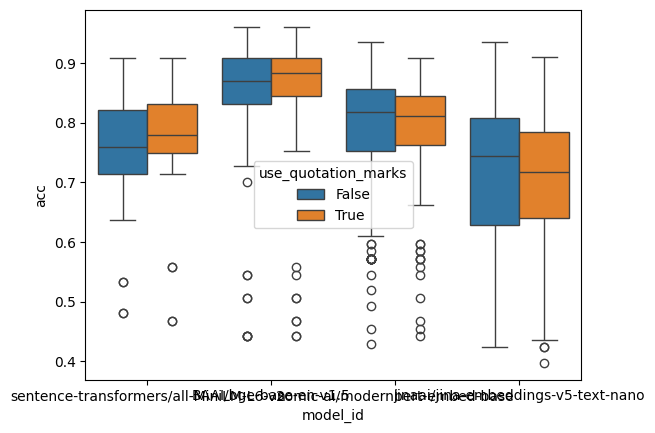

In [ ]:
sns.boxplot(data=results_df, y="acc", x="model_id", hue="use_quotation_marks")

<Axes: xlabel='acc', ylabel='Density'>

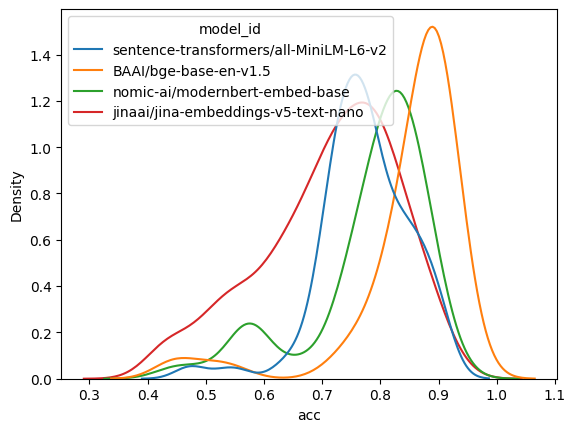

In [ ]:
sns.kdeplot(results_df, x="acc", hue="model_id")

In [ ]:
results_df.model_id.unique()

array(['sentence-transformers/all-MiniLM-L6-v2', 'BAAI/bge-base-en-v1.5',
       'nomic-ai/modernbert-embed-base',
       'jinaai/jina-embeddings-v5-text-nano'], dtype=object)

In [ ]:
intended_pooling = (results_df[
  ((results_df["model_id"] == 'sentence-transformers/all-MiniLM-L6-v2') & (results_df["method"] == "mean")) |
  ((results_df["model_id"] == 'BAAI/bge-base-en-v1.5') & (results_df["method"] == "cls")) |
  ((results_df["model_id"] == 'nomic-ai/modernbert-embed-base') & (results_df["method"] == "mean")) |
  ((results_df["model_id"] == 'jinaai/jina-embeddings-v5-text-nano') & (results_df["method"] == "last"))
])

<Axes: xlabel='acc', ylabel='Density'>

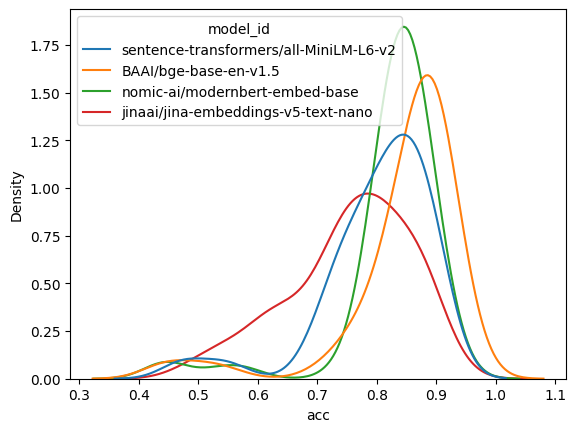

In [ ]:
sns.kdeplot(intended_pooling, x="acc", hue="model_id")

<Axes: xlabel='acc', ylabel='Density'>

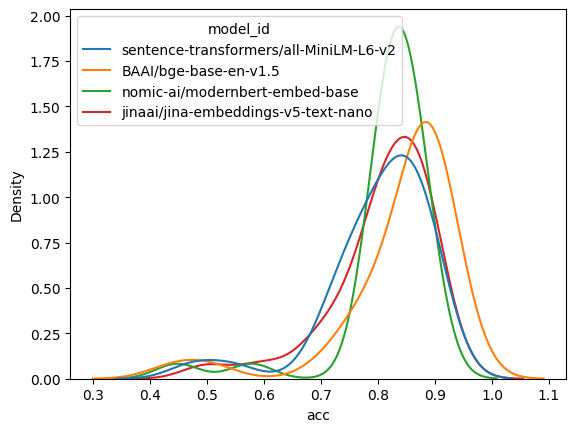

In [ ]:
intended_prefix = (intended_pooling[intended_pooling["use_prefix"] == True])
sns.kdeplot(intended_prefix, x="acc", hue="model_id")

In [ ]:
from scipy.stats import kruskal

groups_emb = [g["acc"].values for _, g in intended_prefix.groupby("model_id", observed=True)]
stat, p = kruskal(*groups_emb)
print(f"stat={stat}, p={p}")

stat=19.08610175747862, p=0.0002624170677436085


In [ ]:
intended_numeric = intended_prefix.copy()
intended_numeric["use_quotation_marks"] = intended_numeric["use_quotation_marks"].replace({False: 0, True: 1})
intended_numeric["use_averaged_probes"] = intended_numeric["use_averaged_probes"].replace({False: 0, True: 1})
intended_numeric["params"] = intended_numeric["use_quotation_marks"].astype(str) + "+" + intended_numeric["use_averaged_probes"].astype(str)

/tmp/ipykernel_1374/1689952943.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  intended_numeric["use_quotation_marks"] = intended_numeric["use_quotation_marks"].replace({False: 0, True: 1})
/tmp/ipykernel_1374/1689952943.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  intended_numeric["use_averaged_probes"] = intended_numeric["use_averaged_probes"].replace({False: 0, True: 1})


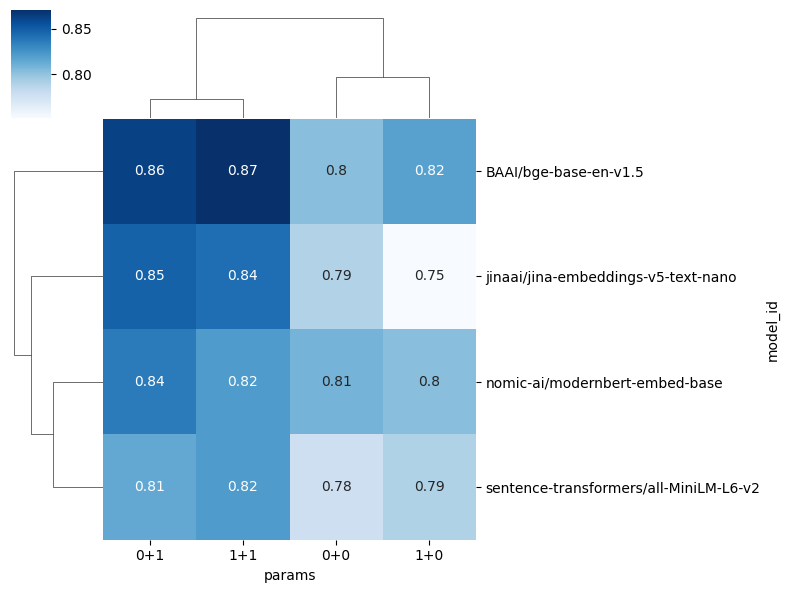

In [ ]:
pivot = intended_numeric.groupby(["model_id", "params"], observed=True)["acc"].mean().unstack()
sns.clustermap(pivot, cmap="Blues", figsize=(8,6), annot=True)

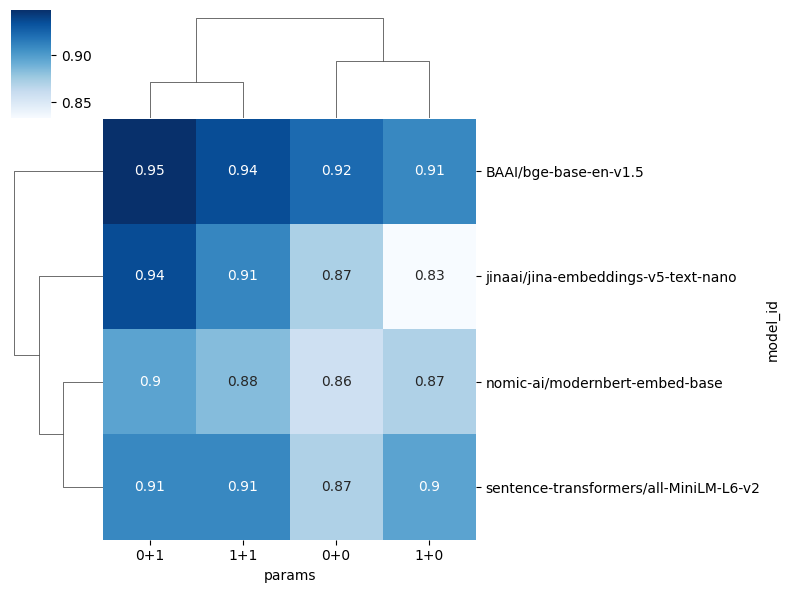

In [ ]:
pivot = intended_numeric.groupby(["model_id", "params"], observed=True)["acc"].max().unstack()
sns.clustermap(pivot, cmap="Blues", figsize=(8,6), annot=True)

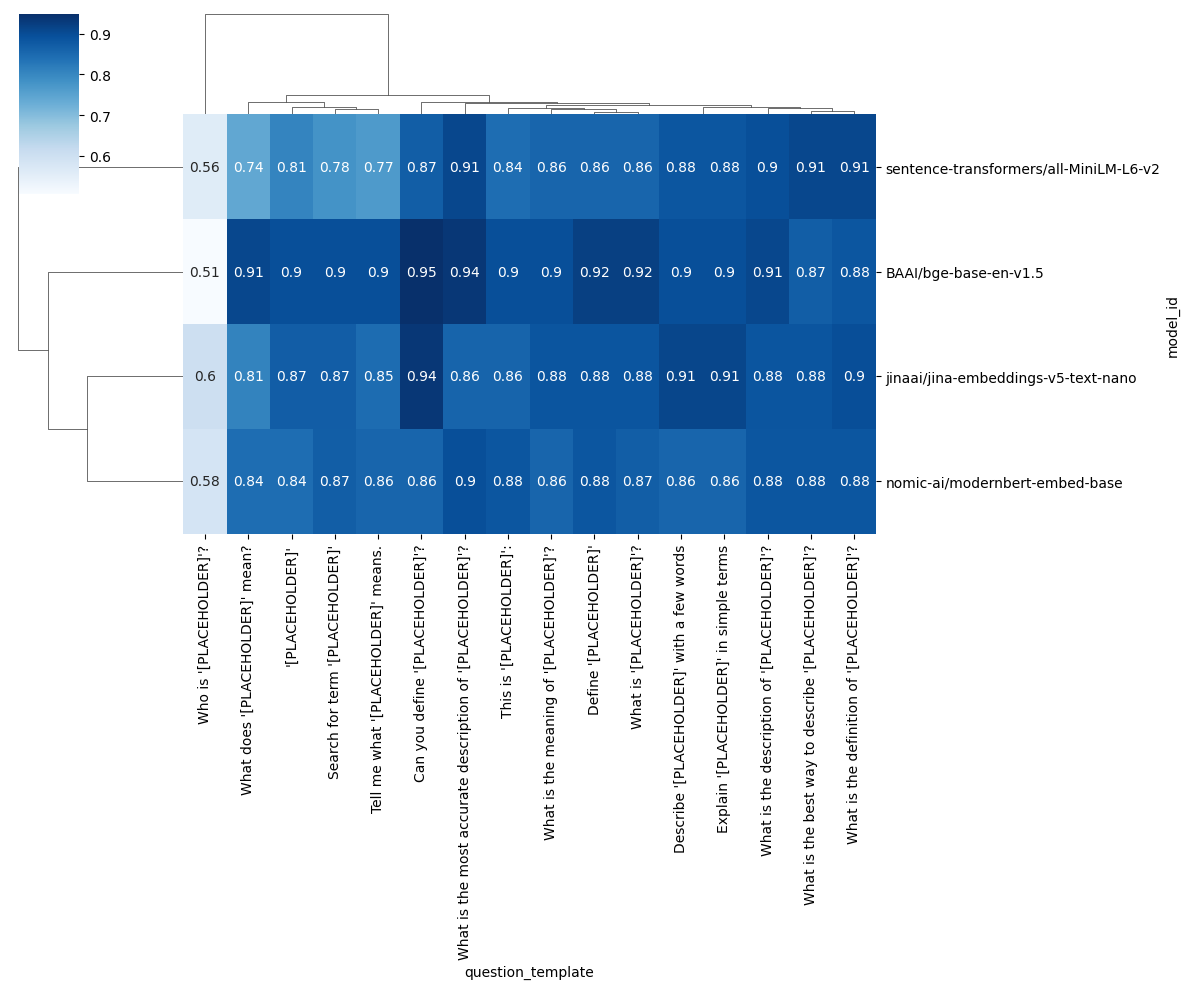

In [ ]:
pivot = intended_numeric.groupby(["model_id", "question_template"], observed=True)["acc"].max().unstack()
sns.clustermap(pivot, cmap="Blues", figsize=(12,10), annot=True)

In [ ]:
df_numeric = results_df.copy()
df_numeric["method"] = df_numeric["method"].replace({"mean": 0, "cls": 1, "last": 2})
df_numeric["use_quotation_marks"] = df_numeric["use_quotation_marks"].replace({False: 0, True: 1})
df_numeric["use_averaged_probes"] = df_numeric["use_averaged_probes"].replace({False: 0, True: 1})
df_numeric["use_prefix"] = df_numeric["use_prefix"].replace({False: 0, True: 1})

/tmp/ipykernel_1374/387411873.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_numeric["method"] = df_numeric["method"].replace({"mean": 0, "cls": 1, "last": 2})
/tmp/ipykernel_1374/387411873.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_numeric["use_quotation_marks"] = df_numeric["use_quotation_marks"].replace({False: 0, True: 1})
/tmp/ipykernel_1374/387411873.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `re

In [ ]:
df_numeric["params"] = df_numeric["use_quotation_marks"].astype(str) + "+" + df_numeric["use_averaged_probes"].astype(str) + "+" + df_numeric["use_prefix"].astype(str) + "+" + df_numeric["method"].astype(str)

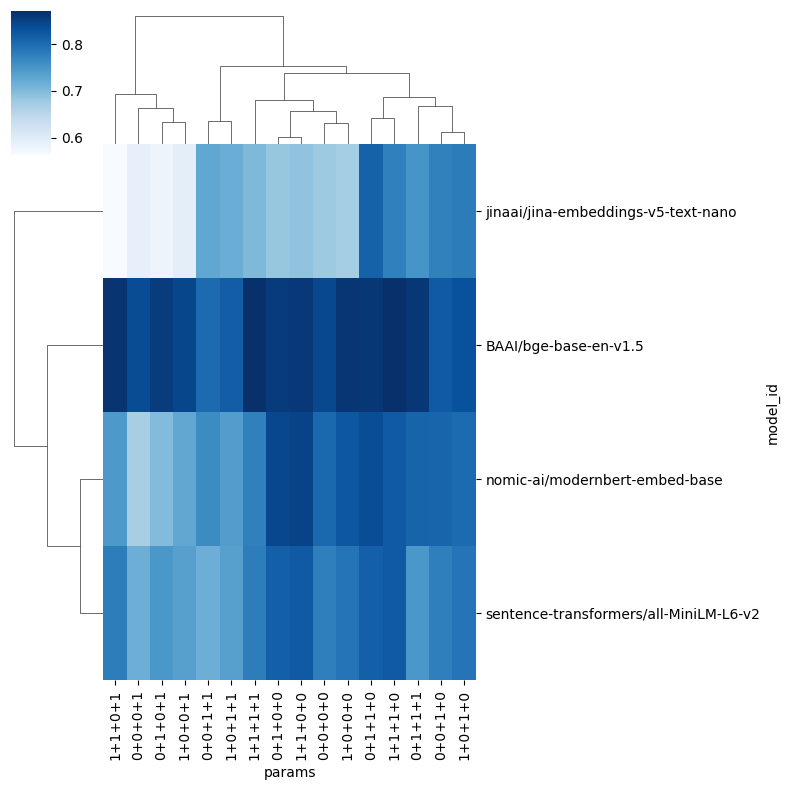

In [ ]:
pivot = df_numeric.groupby(["model_id", "params"], observed=True)["acc"].mean().unstack().dropna(axis=1)
sns.clustermap(pivot, cmap="Blues", figsize=(8,8))

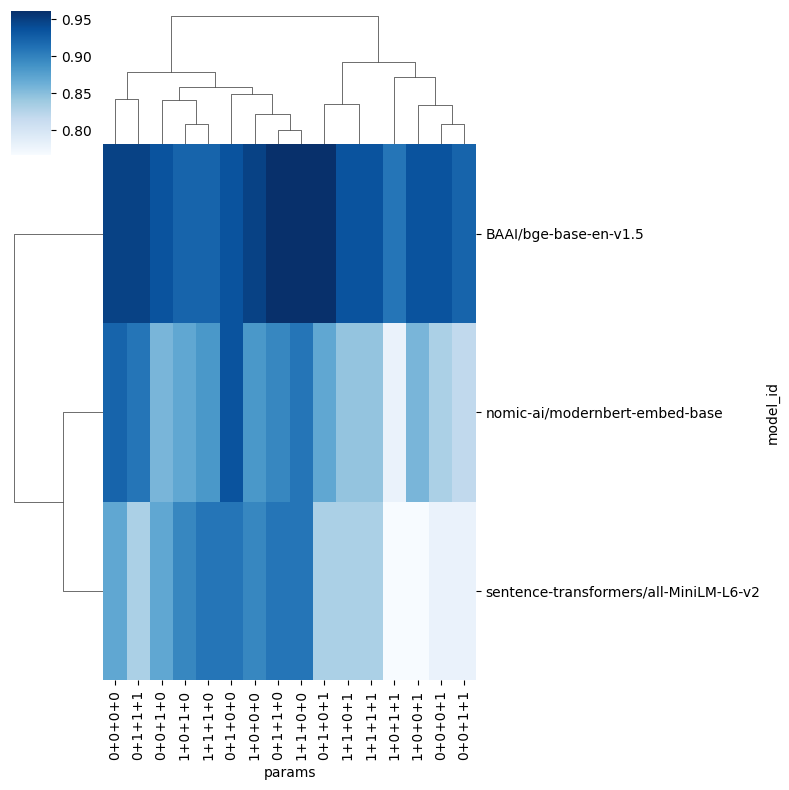

In [ ]:
pivot = df_numeric.groupby(["model_id", "params"])["acc"].max().unstack()
sns.clustermap(pivot, cmap="Blues", figsize=(8,8))

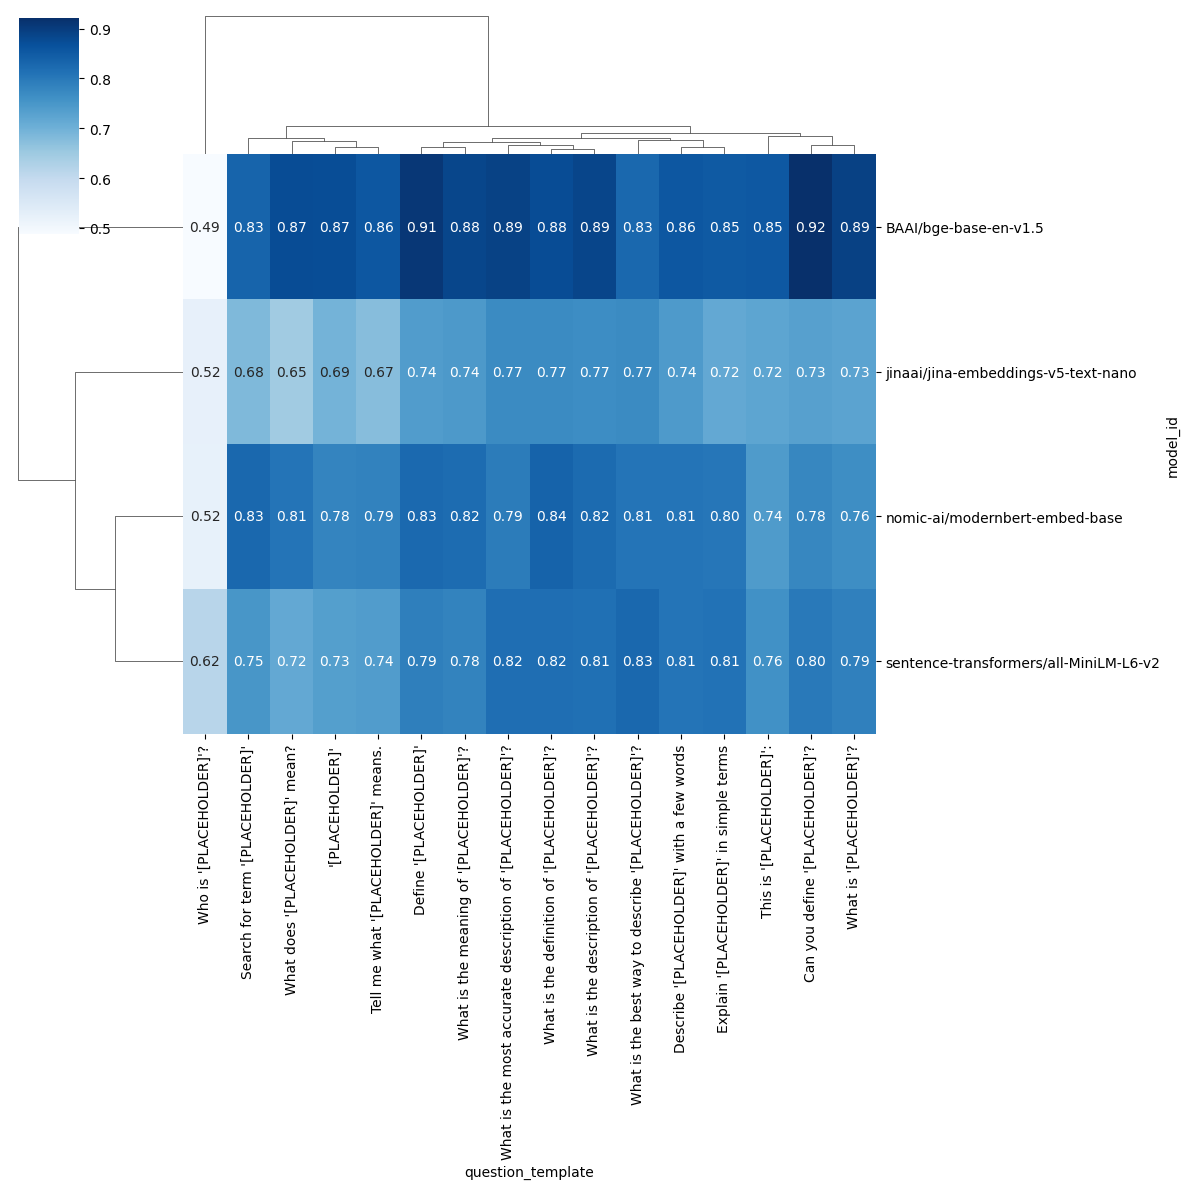

In [ ]:
pivot = results_df.groupby(["model_id", "question_template"])["acc"].mean().unstack()
sns.clustermap(pivot, cmap="Blues", annot=True, fmt=".2f", figsize=(12,12))

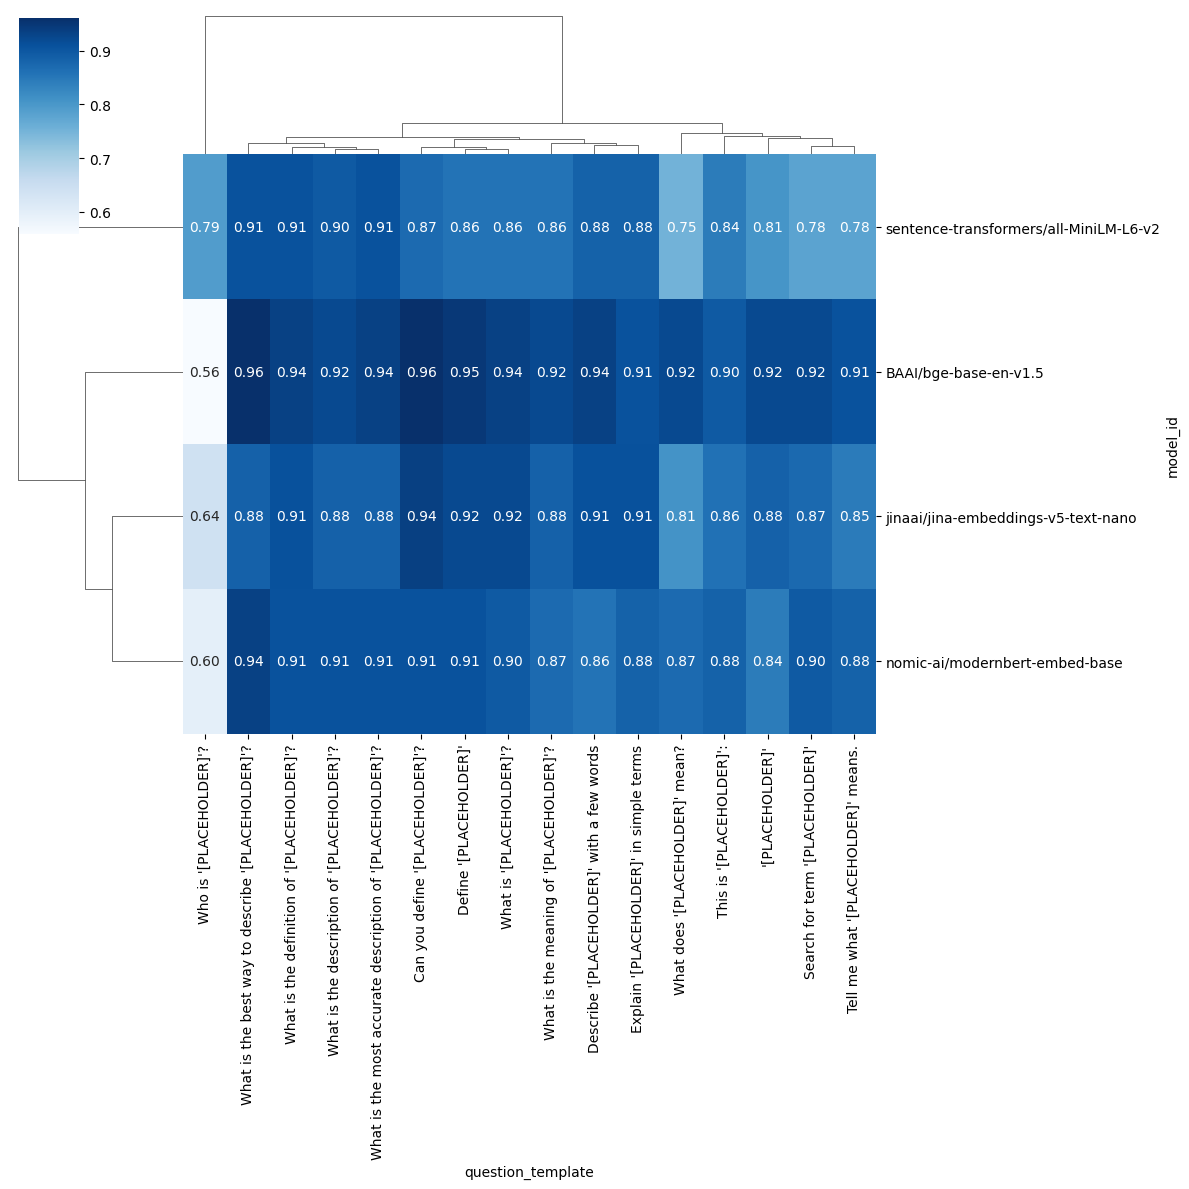

In [ ]:
pivot = results_df.groupby(["model_id", "question_template"])["acc"].max().unstack()
sns.clustermap(pivot, cmap="Blues", annot=True, fmt=".2f", figsize=(12,12))

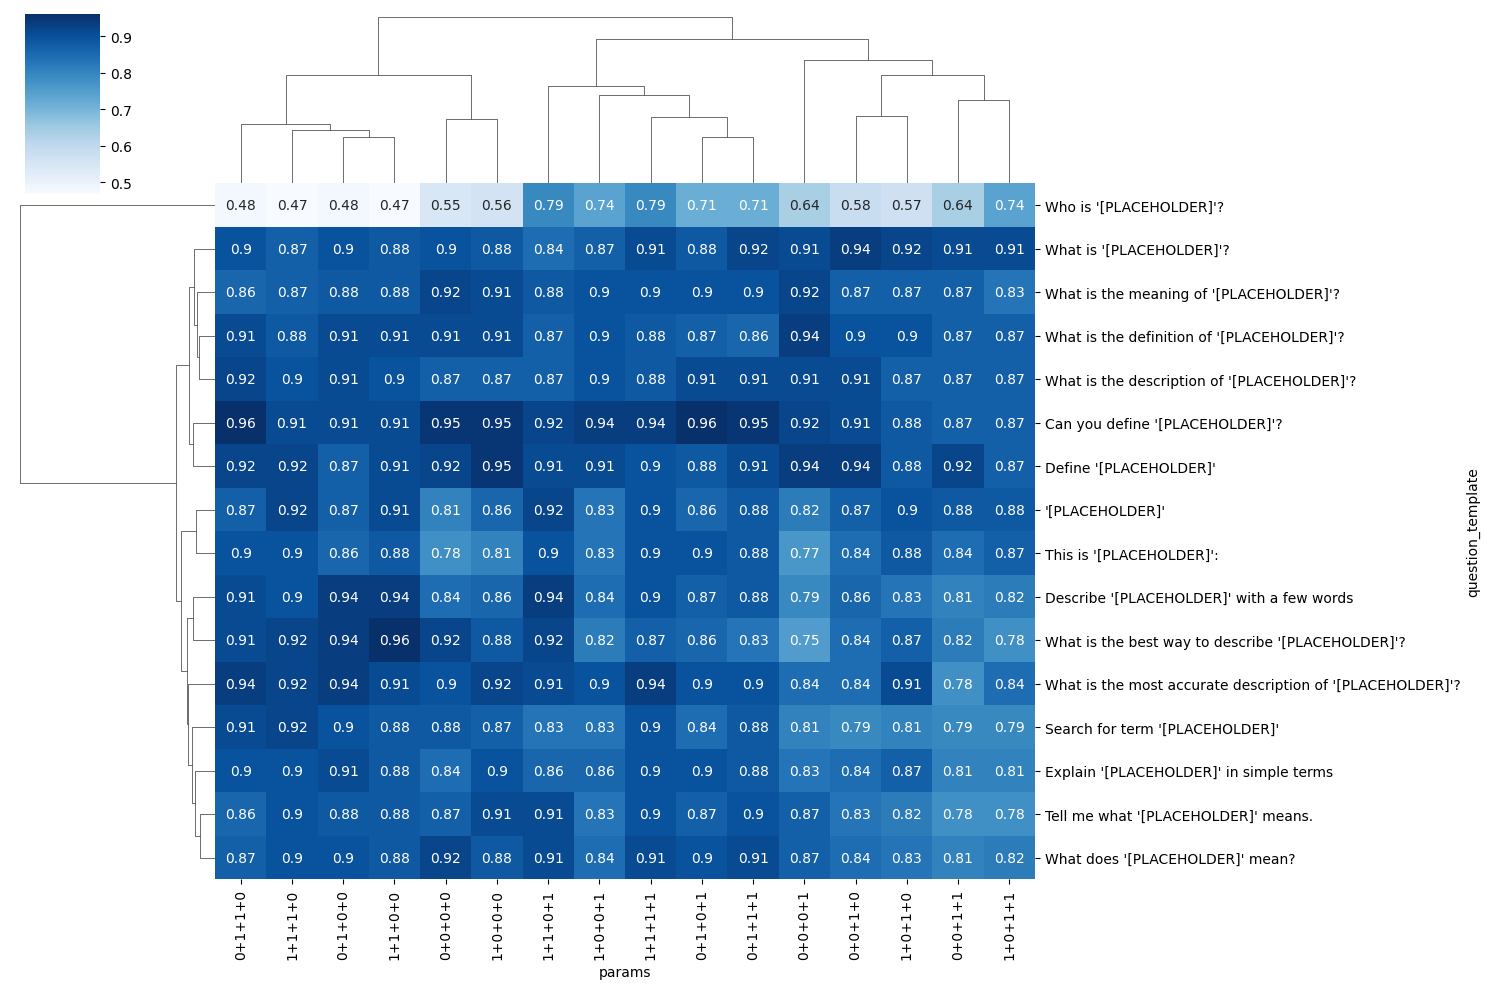

In [ ]:
pivot = df_numeric.groupby(["question_template", "params"])["acc"].max().unstack()
sns.clustermap(pivot, cmap="Blues", annot=True, figsize=(15,10))

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
for model in results_df.model_id.unique():
  data = results_df[(results_df["model_id"] == model) & (results_df["question_template"] != "Who is '[PLACEHOLDER]'?")]

  dummy_data = pd.get_dummies(data.drop(columns=["acc", "model_id"]))
  X = dummy_data
  y = data["acc"]
  rf = RandomForestRegressor().fit(X, y)

  importances = pd.Series(rf.feature_importances_, index=dummy_data.columns).sort_values(ascending=False)
  print(model)
  print(importances)
  print()

sentence-transformers/all-MiniLM-L6-v2
method_mean                                                                    0.197928
method_cls                                                                     0.154480
use_averaged_probes                                                            0.110915
question_template_What does '[PLACEHOLDER]' mean?                              0.108650
question_template_Tell me what '[PLACEHOLDER]' means.                          0.091722
question_template_'[PLACEHOLDER]'                                              0.074850
question_template_Search for term '[PLACEHOLDER]'                              0.053694
use_quotation_marks                                                            0.053225
question_template_This is '[PLACEHOLDER]':                                     0.043635
question_template_What is the definition of '[PLACEHOLDER]'?                   0.022806
question_template_What is the best way to describe '[PLACEHOLDER]'?            0.

In [ ]:
intended_numeric.sort_values("acc", ascending=False).head(20)

,acc,model_id,question_template,use_quotation_marks,use_averaged_probes,use_prefix,method,params
109,0.948052,BAAI/bge-base-en-v1.5,Can you define '[PLACEHOLDER]'?,0,1,True,cls,0+1
68,0.935897,jinaai/jina-embeddings-v5-text-nano,Can you define '[PLACEHOLDER]'?,0,1,True,last,0+1
85,0.935065,BAAI/bge-base-en-v1.5,What is the most accurate description of '[PLA...,1,1,True,cls,1+1
77,0.935065,BAAI/bge-base-en-v1.5,Can you define '[PLACEHOLDER]'?,1,1,True,cls,1+1
489,0.922078,BAAI/bge-base-en-v1.5,Define '[PLACEHOLDER]',0,0,True,cls,0+0
123,0.922078,BAAI/bge-base-en-v1.5,What is '[PLACEHOLDER]'?,0,1,True,cls,0+1
83,0.910256,jinaai/jina-embeddings-v5-text-nano,Describe '[PLACEHOLDER]' with a few words,0,1,True,last,0+1
44,0.910256,jinaai/jina-embeddings-v5-text-nano,Explain '[PLACEHOLDER]' in simple terms,1,1,True,last,1+1
79,0.909091,BAAI/bge-base-en-v1.5,What does '[PLACEHOLDER]' mean?,1,1,True,cls,1+1
91,0.909091,BAAI/bge-base-en-v1.5,What is '[PLACEHOLDER]'?,1,1,True,cls,1+1


In [ ]:
results_df[results_df["model_id"] == "BAAI/bge-base-en-v1.5"].groupby("use_prefix")["acc"].agg(["min", "max", "mean", "std"])

,min,max,mean,std
use_prefix,,,,
False,0.441558,0.961039,0.854099,0.101510
True,0.441558,0.961039,0.842938,0.109065


In [ ]:
intended_mean = intended_numeric["acc"].mean()
intended_numeric[intended_numeric["acc"] > intended_mean].groupby(["model_id", "question_template"])["acc"].agg(["min", "max", "mean", "std"]).sort_values("mean", ascending=False)

min  \
model_id                               question_template                                              
BAAI/bge-base-en-v1.5                  What is '[PLACEHOLDER]'?                            0.909091   
                                       Can you define '[PLACEHOLDER]'?                     0.870130   
                                       Define '[PLACEHOLDER]'                              0.870130   
jinaai/jina-embeddings-v5-text-nano    Can you define '[PLACEHOLDER]'?                     0.871795   
                                       Describe '[PLACEHOLDER]' with a few words           0.884615   
BAAI/bge-base-en-v1.5                  Tell me what '[PLACEHOLDER]' means.                 0.896104   
                                       What is the most accurate description of '[PLAC...  0.844156   
sentence-transformers/all-MiniLM-L6-v2 What is the definition of '[PLACEHOLDER]'?          0.870130   
BAAI/bge-base-en-v1.5                  Explain '[PLACEHOLDER]' in simple terms             0.883117   
nomic-ai/modernbert-embed-base         What is the most accurate description of '[PLAC...  0.883117   
BAAI/bge-base-en-v1.5                  Search for term '[PLACEHOLDER]'                     0.883117   
                                       '[PLACEHOLDER]'                                     0.883117   
                                       What is the description of '[PLACEHOLDER]'?         0.870130   
                                       What does '[PLACEHOLDER]' mean?                     0.818182   
jinaai/jina-embeddings-v5-text-nano    What is the meaning of '[PLACEHOLDER]'?             0.871795   
BAAI/bge-base-en-v1.5                  This is '[PLACEHOLDER]':                            0.844156   
                                       What is the meaning of '[PLACEHOLDER]'?             0.831169   
jinaai/jina-embeddings-v5-text-nano    What is the best way to describe '[PLACEHOLDER]'?   0.858974   
                                       Search for term '[PLACEHOLDER]'                     0.871795   
                                       What is the definition of '[PLACEHOLDER]'?          0.820513   
sentence-transformers/all-MiniLM-L6-v2 Explain '[PLACEHOLDER]' in simple terms             0.844156   
                                       What is the description of '[PLACEHOLDER]'?         0.818182   
BAAI/bge-base-en-v1.5                  Describe '[PLACEHOLDER]' with a few words           0.818182   
nomic-ai/modernbert-embed-base         What is the definition of '[PLACEHOLDER]'?          0.831169   
                                       Define '[PLACEHOLDER]'                              0.844156   
jinaai/jina-embeddings-v5-text-nano    Explain '[PLACEHOLDER]' in simple terms             0.833333   
sentence-transformers/all-MiniLM-L6-v2 What is the best way to describe '[PLACEHOLDER]'?   0.818182   
                                       What is the most accurate description of '[PLAC...  0.818182   
BAAI/bge-base-en-v1.5                  What is the definition of '[PLACEHOLDER]'?          0.831169   
jinaai/jina-embeddings-v5-text-nano    Define '[PLACEHOLDER]'                              0.820513   
                                       What is '[PLACEHOLDER]'?                            0.846154   
sentence-transformers/all-MiniLM-L6-v2 Can you define '[PLACEHOLDER]'?                     0.844156   
nomic-ai/modernbert-embed-base         What is the best way to describe '[PLACEHOLDER]'?   0.844156   
sentence-transformers/all-MiniLM-L6-v2 Describe '[PLACEHOLDER]' with a few words           0.831169   
nomic-ai/modernbert-embed-base         Search for term '[PLACEHOLDER]'                     0.844156   
                                       What is the description of '[PLACEHOLDER]'?         0.818182   
jinaai/jina-embeddings-v5-text-nano    What is the description of '[PLACEHOLDER]'?         0.820513   
nomic-ai/modernbert-embed-base         Explain '[PLACEHOLDER]' in simple terms 

In [ ]:
intended_numeric[intended_numeric["acc"] > intended_mean].groupby("question_template")["acc"].agg(["min", "max", "mean", "std"]).sort_values("mean", ascending=False)

,min,max,mean,std
question_template,,,,
Can you define '[PLACEHOLDER]'?,0.844156,0.948052,0.877836,0.036015
Search for term '[PLACEHOLDER]',0.844156,0.896104,0.873060,0.019221
What is the most accurate description of '[PLACEHOLDER]'?,0.818182,0.935065,0.872854,0.037703
What is the definition of '[PLACEHOLDER]'?,0.820513,0.909091,0.872354,0.026676
What is '[PLACEHOLDER]'?,0.831169,0.922078,0.871539,0.031864
Define '[PLACEHOLDER]',0.818182,0.922078,0.868542,0.032874
Explain '[PLACEHOLDER]' in simple terms,0.833333,0.910256,0.866672,0.024275
What is the description of '[PLACEHOLDER]'?,0.818182,0.909091,0.866300,0.030221
What is the best way to describe '[PLACEHOLDER]'?,0.818182,0.909091,0.861749,0.031566


In [ ]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
  print(results_df.groupby(["model_id", "question_template"])["acc"].agg(["min", "max", "mean", "std"]).sort_values("mean", ascending=False))

                                                                                                min  \
model_id                               question_template                                              
BAAI/bge-base-en-v1.5                  Can you define '[PLACEHOLDER]'?                     0.870130   
                                       Define '[PLACEHOLDER]'                              0.870130   
                                       What is '[PLACEHOLDER]'?                            0.844156   
                                       What is the most accurate description of '[PLAC...  0.779221   
                                       What is the description of '[PLACEHOLDER]'?         0.844156   
                                       What is the meaning of '[PLACEHOLDER]'?             0.831169   
                                       What is the definition of '[PLACEHOLDER]'?          0.831169   
                                       What does '[PLACEHOLDER]' mean?   

# Earlier tests

In [ ]:
subresults = pd.DataFrame(print_results(use_averaged_probes=False, verbose=False), columns=results_df.columns)
results_df = pd.concat([results_df, subresults], ignore_index=True)

SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=False, pooling_method=mean, use_averaged_probes=False
Example query: "What is the definition of 'human'?"
Accuracy: 91.80%

SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=False, pooling_method=cls, use_averaged_probes=False
Example query: "What is the definition of 'human'?"
Accuracy: 77.05%

SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=True, pooling_method=mean, use_averaged_probes=False
Example query: "What is the definition of 'human'?"
Accuracy: 91.80%

SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=True, pooling_method=cls, use_averaged_probes=False
Example query: "What is the definition of 'human'?"
Accuracy: 77.05%



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-base-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Building probe vectors …
Prototype vectors cached.
Building a collection of probe vectors …
Collections of prototype vectors cached.
BAAI/BGE-BASE-EN-V1.5: use_prefix=False, pooling_method=mean, use_averaged_probes=False
Example query: "What is the definition of 'human'?"
Accuracy: 86.89%

BAAI/BGE-BASE-EN-V1.5: use_prefix=False, pooling_method=cls, use_averaged_probes=False
Example query: "What is the definition of 'human'?"
Accuracy: 86.89%

BAAI/BGE-BASE-EN-V1.5: use_prefix=True, pooling_method=mean, use_averaged_probes=False
Example query: "Represent this sentence for searching relevant passages: What is the definition of 'human'?"
Accuracy: 83.61%

BAAI/BGE-BASE-EN-V1.5: use_prefix=True, pooling_method=cls, use_averaged_probes=False
Example query: "Represent this sentence for searching relevant passages: What is the definition of 'human'?"
Accuracy: 83.61%



Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

Building probe vectors …
Prototype vectors cached.
Building a collection of probe vectors …
Collections of prototype vectors cached.
NOMIC-AI/MODERNBERT-EMBED-BASE: use_prefix=False, pooling_method=mean, use_averaged_probes=False
Example query: "What is the definition of 'human'?"
Accuracy: 81.97%

NOMIC-AI/MODERNBERT-EMBED-BASE: use_prefix=False, pooling_method=cls, use_averaged_probes=False
Example query: "What is the definition of 'human'?"
Accuracy: 77.05%

NOMIC-AI/MODERNBERT-EMBED-BASE: use_prefix=True, pooling_method=mean, use_averaged_probes=False
Example query: "search_query: What is the definition of 'human'?"
Accuracy: 77.05%

NOMIC-AI/MODERNBERT-EMBED-BASE: use_prefix=True, pooling_method=cls, use_averaged_probes=False
Example query: "search_query: What is the definition of 'human'?"
Accuracy: 75.41%

(0.9180327868852459, 'sentence-transformers/all-MiniLM-L6-v2', True, False, True, 'mean')
(0.9180327868852459, 'sentence-transformers/all-MiniLM-L6-v2', True, False, False, 'm

/tmp/ipykernel_4504/430059756.py:2: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results_df = pd.concat([results_df, subresults], ignore_index=True)


In [ ]:
subresults = pd.DataFrame(print_results(use_averaged_probes=True, verbose=False), columns=results_df.columns)
results_df = pd.concat([results_df, subresults], ignore_index=True)


SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=False, pooling_method=mean, use_averaged_probes=True
Example query: "What is the definition of 'human'?"
Accuracy: 86.89%


SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=False, pooling_method=cls, use_averaged_probes=True
Example query: "What is the definition of 'human'?"
Accuracy: 80.33%


SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=True, pooling_method=mean, use_averaged_probes=True
Example query: "What is the definition of 'human'?"
Accuracy: 86.89%


SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=True, pooling_method=cls, use_averaged_probes=True
Example query: "What is the definition of 'human'?"
Accuracy: 80.33%


BAAI/BGE-BASE-EN-V1.5: use_prefix=False, pooling_method=mean, use_averaged_probes=True
Example query: "What is the definition of 'human'?"
Accuracy: 83.61%


BAAI/BGE-BASE-EN-V1.5: use_prefix=False, pooling_method=cls, use_averaged_probes=True
Example query: "What is the definition of 'human'?"
Accuracy

In [ ]:
subresults = pd.DataFrame(print_results(use_question_format=False, use_averaged_probes=True, verbose=False), columns=results_df.columns)
results_df = pd.concat([results_df, subresults], ignore_index=True)

SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=False, pooling_method=mean, use_averaged_probes=True
Example query: 'human'
Accuracy: 75.41%


SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=False, pooling_method=cls, use_averaged_probes=True
Example query: 'human'
Accuracy: 68.85%


SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=True, pooling_method=mean, use_averaged_probes=True
Example query: 'human'
Accuracy: 75.41%


SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=True, pooling_method=cls, use_averaged_probes=True
Example query: 'human'
Accuracy: 68.85%


BAAI/BGE-BASE-EN-V1.5: use_prefix=False, pooling_method=mean, use_averaged_probes=True
Example query: 'human'
Accuracy: 85.25%


BAAI/BGE-BASE-EN-V1.5: use_prefix=False, pooling_method=cls, use_averaged_probes=True
Example query: 'human'
Accuracy: 83.61%


BAAI/BGE-BASE-EN-V1.5: use_prefix=True, pooling_method=mean, use_averaged_probes=True
Example query: 'Represent this sentence for searching relevant passages: huma

In [ ]:
subresults = pd.DataFrame(print_results(use_question_format=False, use_averaged_probes=False, verbose=False), columns=results_df.columns)
results_df = pd.concat([results_df, subresults], ignore_index=True)

SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=False, pooling_method=mean, use_averaged_probes=False
Example query: 'human'
Accuracy: 73.77%

SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=False, pooling_method=cls, use_averaged_probes=False
Example query: 'human'
Accuracy: 70.49%

SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=True, pooling_method=mean, use_averaged_probes=False
Example query: 'human'
Accuracy: 73.77%

SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=True, pooling_method=cls, use_averaged_probes=False
Example query: 'human'
Accuracy: 70.49%

BAAI/BGE-BASE-EN-V1.5: use_prefix=False, pooling_method=mean, use_averaged_probes=False
Example query: 'human'
Accuracy: 80.33%

BAAI/BGE-BASE-EN-V1.5: use_prefix=False, pooling_method=cls, use_averaged_probes=False
Example query: 'human'
Accuracy: 83.61%

BAAI/BGE-BASE-EN-V1.5: use_prefix=True, pooling_method=mean, use_averaged_probes=False
Example query: 'Represent this sentence for searching relevant passages: hum

In [ ]:
results_df.sort_values("acc", ascending=False)

,acc,model_id,use_question_format,use_averaged_probes,use_prefix,method
0,0.918033,sentence-transformers/all-MiniLM-L6-v2,True,False,False,mean
2,0.918033,sentence-transformers/all-MiniLM-L6-v2,True,False,True,mean
14,0.918033,sentence-transformers/all-MiniLM-L6-v2,True,False,True,mean
12,0.918033,sentence-transformers/all-MiniLM-L6-v2,True,False,False,mean
43,0.885246,BAAI/bge-base-en-v1.5,False,True,True,cls
16,0.868852,BAAI/bge-base-en-v1.5,True,False,False,mean
26,0.868852,sentence-transformers/all-MiniLM-L6-v2,True,True,True,mean
17,0.868852,BAAI/bge-base-en-v1.5,True,False,False,cls
5,0.868852,BAAI/bge-base-en-v1.5,True,False,False,cls
4,0.868852,BAAI/bge-base-en-v1.5,True,False,False,mean


In [ ]:
results_df.groupby("model_id")["acc"].mean().sort_values(ascending=False)

,acc
model_id,
BAAI/bge-base-en-v1.5,0.847541
sentence-transformers/all-MiniLM-L6-v2,0.793443
nomic-ai/modernbert-embed-base,0.789344


In [ ]:
results_df.groupby(["model_id", "use_question_format"])["acc"].mean().sort_values(ascending=False)

model_id                                use_question_format
BAAI/bge-base-en-v1.5                   True                   0.848361
                                        False                  0.846311
sentence-transformers/all-MiniLM-L6-v2  True                   0.841530
nomic-ai/modernbert-embed-base          True                   0.797814
                                        False                  0.776639
sentence-transformers/all-MiniLM-L6-v2  False                  0.721311
Name: acc, dtype: float64

In [ ]:
results_df.groupby(["model_id", "use_prefix"])["acc"].mean().sort_values(ascending=False)

model_id                                use_prefix
BAAI/bge-base-en-v1.5                   False         0.847541
                                        True          0.847541
sentence-transformers/all-MiniLM-L6-v2  True          0.793443
                                        False         0.793443
nomic-ai/modernbert-embed-base          False         0.790164
                                        True          0.788525
Name: acc, dtype: float64

In [ ]:
results_df.groupby(["model_id", "method"])["acc"].mean().sort_values(ascending=False)

model_id                                method
BAAI/bge-base-en-v1.5                   cls       0.850820
                                        mean      0.844262
sentence-transformers/all-MiniLM-L6-v2  mean      0.839344
nomic-ai/modernbert-embed-base          mean      0.809836
                                        cls       0.768852
sentence-transformers/all-MiniLM-L6-v2  cls       0.747541
Name: acc, dtype: float64

In [ ]:
results_df.groupby(["model_id", "use_averaged_probes"])["acc"].mean().sort_values(ascending=False)

model_id                                use_averaged_probes
BAAI/bge-base-en-v1.5                   True                   0.848361
                                        False                  0.846995
nomic-ai/modernbert-embed-base          True                   0.817623
sentence-transformers/all-MiniLM-L6-v2  False                  0.803279
                                        True                   0.778689
nomic-ai/modernbert-embed-base          False                  0.770492
Name: acc, dtype: float64

In [ ]:
print_results()

Example query: "What is the definition of 'human'?"
SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=False, pooling_method=mean
human                 -> animate    probs: [0.5317692  0.46823078] | similarities: [0.6250468 0.4977985]
animal                -> inanimate  probs: [0.49874178 0.5012582 ] | similarities: [0.38631773 0.39135063]
cat                   -> inanimate  probs: [0.49760428 0.50239575] | similarities: [0.32038754 0.32997048]
dog                   -> animate    probs: [0.5111364  0.48886356] | similarities: [0.38116068 0.33660758]
person                -> animate    probs: [0.57084566 0.42915437] | similarities: [0.7016116  0.41630948]
Mary                  -> animate    probs: [0.51466393 0.4853361 ] | similarities: [0.27371672 0.21504423]
Thomas                -> animate    probs: [0.53002226 0.46997774] | similarities: [0.32632238 0.20608869]
robot                 -> inanimate  probs: [0.49037063 0.50962937] | similarities: [0.49311894 0.5316412 ]
AI              

In [ ]:
print_results(use_question_format=False)

Example query: 'human'
SENTENCE-TRANSFORMERS/ALL-MINILM-L6-V2: use_prefix=False, pooling_method=mean
human                 -> animate    probs: [0.5569896  0.44301036] | similarities: [0.6640916  0.43513817]
animal                -> animate    probs: [0.5083749 0.4916251] | similarities: [0.36061257 0.32710975]
cat                   -> animate    probs: [0.5107509  0.48924917] | similarities: [0.28467208 0.24166201]
dog                   -> animate    probs: [0.51451933 0.4854807 ] | similarities: [0.31219742 0.25410378]
person                -> animate    probs: [0.5733036  0.42669642] | similarities: [0.62619686 0.33085424]
Mary                  -> animate    probs: [0.528944   0.47105592] | similarities: [0.25556844 0.13966271]
Thomas                -> animate    probs: [0.54026496 0.459735  ] | similarities: [0.26793784 0.10652838]
robot                 -> inanimate  probs: [0.49575114 0.50424886] | similarities: [0.42088938 0.43788528]
AI                    -> animate    probs: [0

In [ ]:
!pip install --upgrade torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 42.8 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [ ]:
model = AutoModel.from_pretrained(
    "jinaai/jina-embeddings-v5-text-nano",
    trust_remote_code=True,
    #_attn_implementation="flash_attention_2",  # Recommended but optional
    #dtype=torch.bfloat16,  # Recommended for GPUs
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device=device)

# Optional: set truncate_dim and max_length in encode() to control embedding size and input length


query_embeddings.shape

Loading weights:   0%|          | 0/110 [00:00<?, ?it/s]

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/17.2M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/582 [00:00<?, ?B/s]

torch.Size([61, 768])

In [ ]:
_model_cache["jinaai/jina-embeddings-v5-text-nano"] = (AutoTokenizer.from_pretrained("jinaai/jina-embeddings-v5-text-nano"), model)

The repository jinaai/jina-embeddings-v5-text-nano contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/jinaai/jina-embeddings-v5-text-nano .
 You can inspect the repository content at https://hf.co/jinaai/jina-embeddings-v5-text-nano.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


In [ ]:
jina_config = configure("jinaai/jina-embeddings-v5-text-nano")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

The repository jinaai/jina-embeddings-v5-text-nano contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/jinaai/jina-embeddings-v5-text-nano .
 You can inspect the repository content at https://hf.co/jinaai/jina-embeddings-v5-text-nano.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


configuration_jina_embeddings_v5.py:   0%|          | 0.00/137 [00:00<?, ?B/s]

configuration_eurobert.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/jinaai/jina-embeddings-v5-text-nano:
- configuration_eurobert.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/jinaai/jina-embeddings-v5-text-nano:
- configuration_jina_embeddings_v5.py
- configuration_eurobert.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


... (7 outputs left out)

model.safetensors:   0%|          | 0.00/424M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/110 [00:00<?, ?it/s]

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Building probe vectors …
Prototype vectors cached.
Building a collection of probe vectors …
Collections of prototype vectors cached.


In [ ]:
query_embeddings = jina_config.emb_model.encode(
    texts=[f"What is the definition of '{ent}'?" for ent in TEST_ENTITIES],
    task="retrieval",
    prompt_name="query",
)

similarities = query_embeddings @ _prototype_cache[jina_config.emb_model_id].T
probs = softmax(similarities, axis=1)

predicted_labels = []
for entity, prob, sims in zip(TEST_ENTITIES, probs, similarities):
  label_str = "animate" if prob[0] > prob[1] else "inanimate"
  predicted_labels.append(1 if label_str == "animate" else 0)
  print(f"{entity:<{max_entity_len+1}} -> {label_str:<10} probs: {prob} | similarities: {sims}")
acc = accuracy_score(labels, predicted_labels)
print(f"Accuracy: {acc:.2%}")

human                                   -> animate    probs: [0.5186296  0.48137042] | similarities: tensor([0.3213, 0.2467])
animal                                  -> inanimate  probs: [0.4898506 0.5101494] | similarities: tensor([0.2010, 0.2416])
cat                                     -> inanimate  probs: [0.4947382 0.5052618] | similarities: tensor([0.2105, 0.2315])
dog                                     -> inanimate  probs: [0.49148974 0.50851023] | similarities: tensor([0.1631, 0.1972])
person                                  -> animate    probs: [0.5356516  0.46434835] | similarities: tensor([0.3786, 0.2358])
Mary                                    -> animate    probs: [0.5104355  0.48956442] | similarities: tensor([0.1624, 0.1207])
Thomas                                  -> animate    probs: [0.50743675 0.49256328] | similarities: tensor([0.1813, 0.1515])
robot                                   -> inanimate  probs: [0.4827986 0.5172014] | similarities: tensor([0.1969, 0.2657]

/tmp/ipykernel_1374/934194537.py:7: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  similarities = query_embeddings @ _prototype_cache[jina_config.emb_model_id].T


In [ ]:
def print_results(*,
                  models,
                  use_averaged_probes=True,
                  use_prefix=True,
                  verbose=False):
  results = []
  for model_id in (models):
    config = configure(model_id)

    for use_quotation_marks in (True, False):
      if use_quotation_marks:
        to_replace = "[PLACEHOLDER]"
      else:
        to_replace = "'[PLACEHOLDER]'"
      for question_template in questions:
        queries = [question_template.replace(to_replace, test_entity) for test_entity in TEST_ENTITIES]
        if use_prefix:
          queries = [EMB_MODEL_CONFIGS[config.emb_model_id]["query_prefix"] + text for text in queries]
        print(f"Example query: {repr(queries[0])}")

        with torch.no_grad():
          encoded_queries = config.emb_tokenizer(queries, padding=True, truncation=True, return_tensors="pt")

        queries_outputs = config.emb_model(**encoded_queries)

        for method, pooling in zip(("mean", "cls", "last"), (pool_batch, cls_pooling, last_token_pool)):

          query_embeddings = pooling(queries_outputs.last_hidden_state, encoded_queries["attention_mask"])

          if use_averaged_probes:
            prototypes = _prototype_cache[config.emb_model_id].T
            similarities = query_embeddings @ prototypes
            probs = softmax(similarities, axis=1)

            predicted_labels = []

            for entity, prob, sims in zip(TEST_ENTITIES, probs, similarities):
              label_str = "animate" if prob[0] > prob[1] else "inanimate"
              predicted_labels.append(1 if label_str == "animate" else 0)
              if verbose:
                print(f"{entity:<{max_entity_len+1}} -> {label_str:<10} probs: {prob} | similarities: {sims}")
            acc = accuracy_score(labels, predicted_labels)

          else:
            hum_sims = query_embeddings @ _prototype_desc_cache[config.emb_model_id]["animate"].T
            ina_sims = query_embeddings @ _prototype_desc_cache[config.emb_model_id]["inanimate"].T

            predicted_labels = []
            for entity, hum_sim, ina_sim in zip(TEST_ENTITIES, hum_sims, ina_sims):
              max_hum = np.max(hum_sim)
              max_ina = np.max(ina_sim)
              label = 1 if max_hum > max_ina else 0
              predicted_labels.append(label)

              if verbose:
                if label == 1:
                  print(f"{entity} -> most like '{ANIMATE_DESCRIPTIONS[np.argmax(hum_sim)]}' ({max_hum})")
                else:
                  print(f"{entity} -> most like '{INANIMATE_DESCRIPTIONS[np.argmax(ina_sim)]}' ({max_ina})")
            acc = accuracy_score(labels, predicted_labels)
          print(f"{model_id}: question_template={question_template}, use_quotation_marks={use_quotation_marks}, use_prefix={use_prefix}, pooling_method={method}, use_averaged_probes={use_averaged_probes}")
          print(f"Accuracy: {acc:.2%}")
          results.append((acc, model_id, question_template, use_quotation_marks, use_averaged_probes, use_prefix, method))
          print()

  for res in sorted(results, reverse=True):
      print(res)
  return results

In [ ]:
all_jina_results = []
for use_averaged_probes, use_prefix in params:
  print(use_averaged_probes, use_prefix)
  all_jina_results.extend(print_results(models=["jinaai/jina-embeddings-v5-text-nano"], use_averaged_probes=use_averaged_probes, use_prefix=use_prefix))

True True
Example query: "Query: 'human'"
jinaai/jina-embeddings-v5-text-nano: question_template='[PLACEHOLDER]', use_quotation_marks=True, use_prefix=True, pooling_method=mean, use_averaged_probes=True
Accuracy: 83.33%

jinaai/jina-embeddings-v5-text-nano: question_template='[PLACEHOLDER]', use_quotation_marks=True, use_prefix=True, pooling_method=cls, use_averaged_probes=True
Accuracy: 73.08%

jinaai/jina-embeddings-v5-text-nano: question_template='[PLACEHOLDER]', use_quotation_marks=True, use_prefix=True, pooling_method=last, use_averaged_probes=True
Accuracy: 84.62%

Example query: "Query: This is 'human':"
jinaai/jina-embeddings-v5-text-nano: question_template=This is '[PLACEHOLDER]':, use_quotation_marks=True, use_prefix=True, pooling_method=mean, use_averaged_probes=True
Accuracy: 80.77%

jinaai/jina-embeddings-v5-text-nano: question_template=This is '[PLACEHOLDER]':, use_quotation_marks=True, use_prefix=True, pooling_method=cls, use_averaged_probes=True
Accuracy: 65.38%

jinaai

In [ ]:
columns = "acc, model_id, question_template, use_quotation_marks, use_averaged_probes, use_prefix, method".split(", ")
jina_results_df = pd.DataFrame(all_jina_results, columns=columns)

In [ ]:
jina_results_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 384 entries, 0 to 383
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   acc                  384 non-null    float64
 1   model_id             384 non-null    object 
 2   question_template    384 non-null    object 
 3   use_quotation_marks  384 non-null    bool   
 4   use_averaged_probes  384 non-null    bool   
 5   use_prefix           384 non-null    bool   
 6   method               384 non-null    object 
dtypes: bool(3), float64(1), object(3)
memory usage: 13.3+ KB


In [ ]:
import seaborn as sns

<Axes: xlabel='acc', ylabel='Density'>

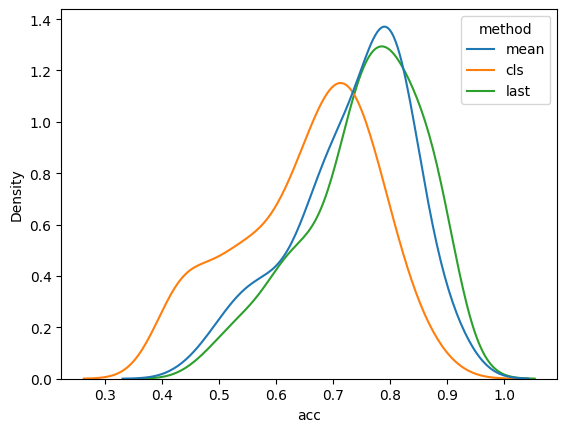

In [ ]:
sns.kdeplot(jina_results_df, x="acc", hue="method")

In [ ]:
initial_results = pd.read_csv("embedding_results.csv")
results = pd.concat([initial_results, jina_results_df])
results.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1152 entries, 0 to 383
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   acc                  1152 non-null   float64
 1   model_id             1152 non-null   object 
 2   question_template    1152 non-null   object 
 3   use_quotation_marks  1152 non-null   bool   
 4   use_averaged_probes  1152 non-null   bool   
 5   use_prefix           1152 non-null   bool   
 6   method               1152 non-null   object 
dtypes: bool(3), float64(1), object(3)
memory usage: 48.4+ KB


<Axes: xlabel='acc', ylabel='Density'>

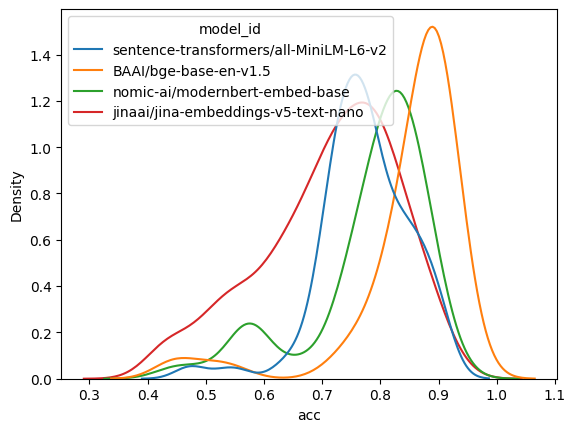

In [ ]:
sns.kdeplot(results, x="acc", hue="model_id")

In [ ]:
results.to_csv("embedding_results_all.csv", index=False)